# 팀 프로젝트2 — 14조: 다음 학년도 중도탈락 고위험 학과는 어디인가
학업지속 지원 대상 학과 선정을 위한 대학알리미 학과별 중도탈락 패널(2023~2026) 분석 및 예측

- 팀: 정승엽, 박유진, 신효주 · 담당교수 박주원
- Colab 정본 링크: https://colab.research.google.com/drive/1JCE1qZSWkixXybo86cDwFJpl4_n-Tbmc?usp=sharing
- GitHub 저장소: https://github.com/202103116-stack/university-dropout-risk-analysis
- 실행 방법: CSV를 올린 뒤 **런타임 → 다시 시작 및 모두 실행**. 처음부터 재실행할 수 있어야 한다(불가하면 −5점).
- 구성: 안내문 5단계 **① 문제 정의 → ② 수집 → ③ 정제 → ④ 분석 → ⑤ 발표**, 그리고 부록(재현성 확인). 기준 문서는 `docs/기준_정리.md`.
- **출처 규칙**: 수치를 출력하는 셀에는 맨 위 주석에 셀 ID(예: `s3-06`)를 둔다. 보고서·발표에 옮길 때 `(출처: 노트북 §③ 셀 s3-06)` 형식으로 붙인다. 출처 없는 수치는 건당 −2점.
- **고정 규칙**: 집단별 탈락률은 `hypotheses-locked-v3` 태그(2026-11-11) 이후에만 계산한다. 분류는 데이터 컬럼만 쓰고 수작업 매핑은 만들지 않는다.

## 0. 환경·경로

In [1]:
# s0-01 환경·경로·스위치
import os, glob, platform, datetime
import numpy as np
import pandas as pd

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 200)

# 원자료 경로 후보: Colab 업로드(/content) → Drive → 로컬(notebook/ 기준 ../data/raw)
FNAME = '교육부_대학알리미_중도탈락 학생 현황 _대학_학과별_20260831.csv'
CANDIDATES = [f'/content/{FNAME}', f'/content/drive/MyDrive/{FNAME}', f'../data/raw/{FNAME}', f'data/raw/{FNAME}']
CANDIDATES += sorted(glob.glob('/content/*중도탈락*.csv')) + sorted(glob.glob('../data/raw/*중도탈락*.csv'))
CSV_PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)
if CSV_PATH is None:
    raise FileNotFoundError('원자료 CSV를 찾지 못했습니다. Colab이면 왼쪽 파일 아이콘으로 CSV를 /content에 올려 주세요.')
if CSV_PATH.startswith('../'):
    PROC_DIR = '../data/processed'
elif CSV_PATH.startswith('data/'):
    PROC_DIR = 'data/processed'
else:
    PROC_DIR = '/content/processed'
FIG_DIR = 'figures'
os.makedirs(PROC_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

# 고정값·되돌림 스위치 (logs/정제로그.md 표 6, 00_문제정의_가설.md와 이름 일치)
RANDOM_STATE = 42
SCOPE = 'general_day'            # 'general_day'(일반 대학 주간, 사전 고정) | 'all'(전체 표본, 민감도 ②)
MIN_ENROLL = 30                  # 직전연도 최소 재적(명), 민감도 10·50
MIN_ENROLL_SENS = [10, 30, 50]
HIGH_PCT = 75                    # 고위험 컷 백분위(상위 25%), 민감도 80·70
RATE_SOURCE = 'published'        # 공시 비율 사용(팀 결정 2026-11-11)
HUFS_CODE = 192                  # 한국외국어대학교 (사이버한국외국어대학교 332와 구분)
B_SUBFIELDS = ['기타유럽어・문학', '기타아시아어・문학']
B_SUBFIELDS_SENS = B_SUBFIELDS + ['국제지역학']   # 민감도 ①
TRAIN_T, TEST_T = [2024, 2025], 2026

print('실행 시각:', datetime.datetime.now().strftime('%Y-%m-%d %H:%M'))
print('Python', platform.python_version(), '| pandas', pd.__version__, '| numpy', np.__version__)
print('CSV_PATH =', CSV_PATH)
print('PROC_DIR =', PROC_DIR, '| FIG_DIR =', FIG_DIR)

실행 시각: 2026-11-12 21:17
Python 3.13.14 | pandas 3.0.6 | numpy 2.5.3
CSV_PATH = ../data/raw/교육부_대학알리미_중도탈락 학생 현황 _대학_학과별_20260831.csv
PROC_DIR = ../data/processed | FIG_DIR = figures


## ① 문제 정의 (15점)
- **무엇을**: 의사결정 질문, 가설 A·B, 판정 규칙, 반대 결과 처리 규칙을 인용한다(코드 없음).
- **왜**: 결과를 보기 전에 고정했다는 것을 보여 주려고. 이 셀은 수정하지 않는다.
- **초안 담당자**: `[팀 입력]` · **검토자**: `[팀 입력]` (`logs/기여도표.md`와 일치)
- **이 단계의 검증 흔적**: git 태그 `hypotheses-locked`(v1, 2026-11-08), `hypotheses-locked-v2`(2026-11-11), `00_문제정의_가설.md` 변경 이력

> `00_문제정의_가설.md` v2 인용 (요약). 상세 판정 규칙은 원문을 따른다.

- **누가**: 한국외국어대학교 학사종합지원센터 (보조: 입학처)
- **무엇을**: 다음 학년도 학업지속 지원(상담·학습지원·복학 안내)을 우선 배치할 학과
- **질문 ①**: 전국 일반 대학 학과 중 어떤 설립유형·지역에서 고위험(상위 25%)이 많은가
- **질문 ②**: 그중 한국외대에서는 어떤 학과군이 고위험인가
- **가설 A (전국 구조)**: 사립·비수도권 학과는 고위험 가능성이 높다.
  - 판정: 대계열·전년도 재적을 통제한 로지스틱 회귀에서 두 오즈비가 모두 1보다 크고 95% CI가 1을 포함하지 않으면 맞음. 하나만이면 부분 맞음, 둘 다 아니면 기각.
- **가설 B (한국외대)**: 비주류 외국어 학과군(소계열 기타유럽어・문학·기타아시아어・문학)은 교내 다른 학과보다 탈락률이 높다.
  - 판정: 2024~2026 합산 비율 차이의 부트스트랩 95% 구간 하한이 0보다 크면 맞음. 아니면 기각하고 '모집(입학처)'으로 재정의.
- **예측 절**: A·B 안에서 모델과 기준선 2개를 같은 k의 정밀도로 비교한다. 판정 임계값 없이 정직하게 보고한다.
- **반대 결과**: 그대로 받아들이고 결론에 맞았다/부분 맞았다/틀렸다를 명시한다.

## ② 수집
- **무엇을**: 원본을 읽고 출처·URL·수집일·이용 조건, 행·열 수, 측정 척도를 출력한다.
- **왜**: 데이터가 공개·실제 자료이고 계획서의 규모와 같다는 것을 확인하려고.
- **초안 담당자**: `[팀 입력]` · **검토자**: `[팀 입력]` (`logs/기여도표.md`와 일치)
- **이 단계의 검증 흔적**: 기대 행·열 수 assert, `docs/수집_기록표.md`와 출력 대조

In [2]:
# s2-01 출처 표기
# [출처 규칙] 이 셀의 수치를 보고서·발표에 옮길 때 '(출처: 노트북 §② 셀 s2-01)'를 붙인다.
SOURCE_INFO = {
    '데이터명': '교육부_대학알리미_중도탈락 학생 현황_대학_학과별',
    '제공처': '공공데이터포털 15164570 (https://www.data.go.kr/data/15164570/fileData.do)',
    '제공기관': '교육부 교육데이터정책과 (원 출처: 대학알리미 대학 정보공시)',
    '이용허락': '공공누리 제1유형 (출처 표시)',
    '포털 수정일 / 파일명 날짜': '2026-09-10 / 20260831',
    '다운로드일': '2026-11-08',
}
for k, v in SOURCE_INFO.items():
    print(f'{k:>16}: {v}')

            데이터명: 교육부_대학알리미_중도탈락 학생 현황_대학_학과별
             제공처: 공공데이터포털 15164570 (https://www.data.go.kr/data/15164570/fileData.do)
            제공기관: 교육부 교육데이터정책과 (원 출처: 대학알리미 대학 정보공시)
            이용허락: 공공누리 제1유형 (출처 표시)
 포털 수정일 / 파일명 날짜: 2026-09-10 / 20260831
           다운로드일: 2026-11-08


In [3]:
# s2-02 원본 읽기
# [출처 규칙] '(출처: 노트북 §② 셀 s2-02)'
# 원본 df_raw는 이후 수정하지 않는다. 정제는 사본 df에서 한다.
df_raw = pd.read_csv(CSV_PATH, encoding='utf-8-sig')
print('행 × 열 =', df_raw.shape)
assert df_raw.shape == (56340, 32), '계획서 기준값(56,340×32)과 다름 → 원자료 버전을 확인'

행 × 열 = (56340, 32)


In [4]:
# s2-03 공시연도별 행 수
# [출처 규칙] '(출처: 노트북 §② 셀 s2-03)'
year_n = df_raw['공시연도'].value_counts().sort_index()
print(year_n.to_string())
assert year_n.to_dict() == {2023: 14350, 2024: 13628, 2025: 13928, 2026: 14434}
print('\n공시연도 × 기준연도 (대부분 기준연도 = 공시연도 − 1, 일부 같은 해)')
print(pd.crosstab(df_raw['공시연도'], df_raw['기준연도']))

공시연도
2023    14350
2024    13628
2025    13928
2026    14434

공시연도 × 기준연도 (대부분 기준연도 = 공시연도 − 1, 일부 같은 해)
기준연도   2022   2023   2024   2025  2026
공시연도                                  
2023  14178    172      0      0     0
2024      0  13484    144      0     0
2025      0      0  13827    101     0
2026      0      0      0  14332   102


In [5]:
# s2-04 컬럼 개요와 측정 척도
# [출처 규칙] '(출처: 노트북 §② 셀 s2-04)'
SCALE = {'공시연도': '등간 또는 명목', '기준연도': '등간 또는 명목', '재적학생': '비율 척도(명)', '계': '비율 척도(명)',
         '중도탈락학생비율': '비율 척도(%)'}
REASONS = ['미등록', '미복학', '자퇴', '학사경고', '학생활동', '유급제적', '재학연한초과', '기타']
SCALE.update({c: '비율 척도(명)' for c in REASONS})
overview = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    '고유값 수': df_raw.nunique(),
    '결측 수': df_raw.isna().sum(),
    '예시값': [df_raw[c].dropna().iloc[0] for c in df_raw.columns],
    '측정 척도': [SCALE.get(c, '명목') for c in df_raw.columns],
})
overview

,dtype,고유값 수,결측 수,예시값,측정 척도
공시연도,int64,4,0,2026,등간 또는 명목
기준연도,int64,5,0,2025,등간 또는 명목
학교코드,int64,250,0,2748,명목
학교명,str,243,0,가야대학교(김해),명목
본분교명,str,5,0,본교,명목
대학구분,str,1,0,대학,명목
학교종류,str,7,0,대학교,명목
설립구분,str,6,0,사립,명목
설립유형,str,2,0,사립,명목
소재지유형,str,2,0,비수도권,명목


## ③ 정제 (`logs/정제로그.md` 표 2 순서)
- **무엇을**: 품질 6대 기준으로 사전 진단하고, 범위를 확정하고, 단계별로 이슈를 표시(flag)·추적한다.
- **왜**: 어떤 이슈가 분석 범위·표본에 영향을 주는지 먼저 보고 처리 여부를 정하려고. 행은 지우지 않고 표시 후 표본에서 제외한다.
- **초안 담당자**: `[팀 입력]` · **검토자**: `[팀 입력]` (`logs/기여도표.md`와 일치)
- **이 단계의 검증 흔적**: 기대값 assert, 단계별 추적표(정제로그 표 5), 처리·건수·근거·영향 로그(표 4), 0행 필터 검사

In [6]:
# s3-00 단계별 추적 도구
# [기준] 행 삭제 금지(표시 후 표본에서 제외), y(비율) 보정 금지, 건수는 코드 계산값만, 0행 필터는 멈춤(assert)
KEY = ['공시연도', '학교코드', '학과코드']
LOG = []          # 정제 처리 로그(정제로그 표 4): 처리·건수·근거·영향
TRACK = {}        # 단계별 추적표(정제로그 표 5)

def log(no, 처리, 건수, 근거, 영향):
    LOG.append({'#': no, '처리': 처리, '건수': 건수, '근거': 근거, '영향': 영향})

def make_flags(d):
    """이슈별 불리언 표. 값은 바꾸지 않는다."""
    f = pd.DataFrame(index=d.index)
    enr, cnt, rate = d['재적학생'], d['계'], d['중도탈락학생비율']
    recomputed = cnt / enr.where(enr > 0) * 100
    f['재적 = 0'] = enr.eq(0)
    f['재적 = 0 이면서 계 > 0'] = enr.eq(0) & cnt.gt(0)
    f['재적 = 0 인데 비율 기록됨(0%)'] = enr.eq(0) & rate.notna()
    f['계 > 재적 (재적 > 0)'] = enr.gt(0) & cnt.gt(enr)
    f['재계산 불일치 (> 0.01%p)'] = (rate - recomputed).abs().gt(0.01)
    f['사유합 ≠ 계'] = cnt.notna() & d[REASONS].sum(axis=1, min_count=1).ne(cnt)
    f['비율 결측'] = rate.isna()
    f['└ 계 결측'] = cnt.isna()
    f['└ 재적 0 (계 있음)'] = rate.isna() & cnt.notna() & enr.eq(0)
    f['폐교'] = d['학교상태'].eq('폐교')
    f['신설'] = d['학교상태'].eq('신설')
    f['소계열 N.C.E.'] = d['표준분류_소계열'].eq('N.C.E.')
    f['중계열 N.C.E'] = d['표준분류_중계열'].eq('N.C.E')
    return f

def rate_valid(d):
    """y로 쓸 수 있는 비율: 재적 > 0, 계·비율 존재 (공시값 그대로)"""
    return d['재적학생'].gt(0) & d['계'].notna() & d['중도탈락학생비율'].notna()

def track(stage, d):
    t = make_flags(d).sum().astype(int)
    TRACK[stage] = pd.concat([pd.Series({'(참고) 행 수': len(d)}), t])
    assert len(d) > 0, f'{stage}: 0행 — 조건을 의심할 것'
    return TRACK[stage]

df = df_raw.copy()     # 정제용 사본
track('① 원본 전체', df);
print('추적 도구 준비 완료. 이슈 항목 수:', len(TRACK['① 원본 전체']) - 1)

추적 도구 준비 완료. 이슈 항목 수: 13


### ③-0 사전 진단 (품질 6대 기준, 읽기 전용)
> 기대값은 계획서 기준값이며 assert로 대조한다. 다르면 셀이 멈춘다.

In [7]:
# s3-01 [완전성] 결측
# [출처 규칙] '(출처: 노트북 §③ 셀 s3-01)'
f0 = make_flags(df)
n_rate_na, n_cnt_na, n_z = f0['비율 결측'].sum(), f0['└ 계 결측'].sum(), f0['└ 재적 0 (계 있음)'].sum()
print(f'비율 결측 {n_rate_na:,} = 계 결측 {n_cnt_na:,} + 재적 0(계 있음) {n_z:,}')
assert (n_rate_na, n_cnt_na, n_z) == (6372, 5569, 803)
miss_by_year = (df.assign(비율결측=f0['비율 결측']).groupby('공시연도')['비율결측'].mean() * 100).round(1)
print('\n공시연도별 비율 결측률(%):'); print(miss_by_year.to_string())

비율 결측 6,372 = 계 결측 5,569 + 재적 0(계 있음) 803

공시연도별 비율 결측률(%):
공시연도
2023     0.8
2024    14.8
2025    14.7
2026    15.2


In [8]:
# s3-02 [유일성] 중복
# [출처 규칙] '(출처: 노트북 §③ 셀 s3-02)'
n_full_dup = int(df.duplicated().sum())
n_key_dup = int(df.duplicated(KEY).sum())
print('완전 중복:', n_full_dup, '| 키(공시연도·학교코드·학과코드) 중복:', n_key_dup)
assert (n_full_dup, n_key_dup) == (0, 0)

완전 중복: 0 | 키(공시연도·학교코드·학과코드) 중복: 0


In [9]:
# s3-03 [유효성] 재적 0, 계 > 재적
# [출처 규칙] '(출처: 노트북 §③ 셀 s3-03)'
cols = ['재적 = 0', '재적 = 0 이면서 계 > 0', '재적 = 0 인데 비율 기록됨(0%)', '계 > 재적 (재적 > 0)']
print(f0[cols].sum().to_string())
assert f0['재적 = 0'].sum() == 2500 and f0['재적 = 0 이면서 계 > 0'].sum() == 1497 and f0['계 > 재적 (재적 > 0)'].sum() == 172
over = df[f0['계 > 재적 (재적 > 0)']]
print(f"\n계 > 재적 172행 중 재적 5명 이하: {(over['재적학생'] <= 5).mean() * 100:.0f}%")
# 재적 0인데 비율이 0%로 기록된 행: 계 > 0인 행도 0%로 적혀 있어 y로 쓸 수 없다 → rate_valid()에서 제외

재적 = 0                  2500
재적 = 0 이면서 계 > 0        1497
재적 = 0 인데 비율 기록됨(0%)    1697
계 > 재적 (재적 > 0)          172

계 > 재적 172행 중 재적 5명 이하: 87%


In [10]:
# s3-04 [정확성] 공시 비율 vs 계 ÷ 재적 × 100
# [출처 규칙] '(출처: 노트북 §③ 셀 s3-04)'
v = df[rate_valid(df)]
gap = (v['중도탈락학생비율'] - v['계'] / v['재적학생'] * 100).abs()
print(f'비교 가능 행: {len(v):,}')
print(f'최대 차이: {gap.max():.4f}%p | 0.01%p 초과: {(gap > 0.01).sum()}행 | 0.005%p 초과: {(gap > 0.005 + 1e-9).sum()}행')
assert gap.max() <= 0.0051, '반올림 수준을 넘는 차이 발견 → RATE_SOURCE 결정 재검토'
# 결론: 차이는 소수 둘째 자리 반올림 수준 → 공시값 사용(RATE_SOURCE='published').
# 계획서의 '68행'은 이 정의로 재현되지 않음(정의 차이로 추정) → 정제로그에 기록

비교 가능 행: 48,271
최대 차이: 0.0050%p | 0.01%p 초과: 0행 | 0.005%p 초과: 89행


In [11]:
# s3-05 [일관성] 사유합, 공백, 표준분류, 한국외대 코드 변동
# [출처 규칙] '(출처: 노트북 §③ 셀 s3-05)'
print('사유합 ≠ 계:', int(f0['사유합 ≠ 계'].sum()))
print('학과명 앞뒤 공백:', int((df['학과명'] != df['학과명'].str.strip()).sum()))

# 표준분류 일관성: 같은 학과명(공백 제거)이 5개교 이상에 있을 때 계열이 학교마다 갈리는가 (전체 원본 기준)
nm = df.assign(학과명s=df['학과명'].str.strip())
g = nm.groupby('학과명s').agg(학교수=('학교코드', 'nunique'), 중계열수=('표준분류_중계열', 'nunique'), 소계열수=('표준분류_소계열', 'nunique'))
g5 = g[g['학교수'] >= 5]
print(f"\n5개교 이상 학과명 {len(g5)}개 중 중계열 갈림 {(g5['중계열수'] > 1).sum()}개 ({(g5['중계열수'] > 1).mean() * 100:.0f}%), "
      f"소계열 갈림 {(g5['소계열수'] > 1).sum()}개 ({(g5['소계열수'] > 1).mean() * 100:.0f}%)")
n = len(df)
print(f"분류 불가 비율: 대계열 '광역계열' {df['표준분류_대계열'].eq('광역계열').mean() * 100:.1f}% (대계열에는 N.C.E. 값이 없음) | "
      f"중계열 N.C.E {f0['중계열 N.C.E'].mean() * 100:.1f}% | 소계열 N.C.E. {f0['소계열 N.C.E.'].mean() * 100:.1f}%")

# 국제지역학 포함 3개 소계열: 2개교 이상 학과명 중 소계열이 갈리는 것
names3 = nm.loc[nm['표준분류_소계열'].isin(B_SUBFIELDS_SENS), '학과명s'].unique()
g3 = nm[nm['학과명s'].isin(names3)].groupby('학과명s').agg(학교수=('학교코드', 'nunique'), 소계열수=('표준분류_소계열', 'nunique'))
g3 = g3[g3['학교수'] >= 2]
print(f"국제지역학 포함 3개 소계열: 2개교 이상 학과명 {len(g3)}개 중 소계열 갈림 {(g3['소계열수'] > 1).sum()}개")

# 한국외대
h = df[df['학교코드'] == HUFS_CODE]
print(f"\n한국외대 2026 공시 소계열 N.C.E.: {h[(h['공시연도'] == 2026) & (h['표준분류_소계열'] == 'N.C.E.')]['학과코드'].nunique()}개 학과")
c25 = set(h.loc[h['공시연도'] == 2025, '학과코드']); c26 = set(h.loc[h['공시연도'] == 2026, '학과코드'])
print(f'한국외대 학과코드 2025→2026: 신규 {len(c26 - c25)}, 소멸 {len(c25 - c26)}')

사유합 ≠ 계: 0
학과명 앞뒤 공백: 1

5개교 이상 학과명 508개 중 중계열 갈림 135개 (27%), 소계열 갈림 232개 (46%)
분류 불가 비율: 대계열 '광역계열' 0.4% (대계열에는 N.C.E. 값이 없음) | 중계열 N.C.E 4.8% | 소계열 N.C.E. 9.4%
국제지역학 포함 3개 소계열: 2개교 이상 학과명 44개 중 소계열 갈림 34개

한국외대 2026 공시 소계열 N.C.E.: 35개 학과
한국외대 학과코드 2025→2026: 신규 38, 소멸 24


In [12]:
# s3-06 [적시성] 폐교·신설, 패널 연결 가능성 (전체 원본 기준)
# [출처 규칙] '(출처: 노트북 §③ 셀 s3-06)'
print('학교상태:', df['학교상태'].value_counts().to_dict())
yrs = df.groupby(['학교코드', '학과코드'])['공시연도'].nunique()
print('학과 수(학교코드·학과코드):', len(yrs), '| 4개년 모두 존재:', int((yrs == 4).sum()))
ok = df[rate_valid(df)][['공시연도', '학교코드', '학과코드']]
prev = ok.assign(공시연도=ok['공시연도'] + 1)
n_pairs = len(ok.merge(prev, on=KEY))
print('전년→당해 연결 쌍 (두 해 모두 재적 > 0, 비율 유효):', n_pairs)

학교상태: {'기존': 55584, '폐교': 493, '신설': 263}
학과 수(학교코드·학과코드): 20158 | 4개년 모두 존재: 9369
전년→당해 연결 쌍 (두 해 모두 재적 > 0, 비율 유효): 29071


### ③-1 ~ ③-10 정제 단계 (정제로그 표 2와 같은 번호)

In [13]:
# s3-11 ③-1 중복 (완전 중복 → 키 중복)
# [출처 규칙] '(출처: 노트북 §③ 셀 s3-11)'
assert df.duplicated().sum() == 0 and df.duplicated(KEY).sum() == 0
log(1, '완전 중복·키 중복 확인', '0 / 0', '안내문: 완전 중복 제거를 첫 단계로', '처리 없음 (제거할 행 없음)')
track('② 중복 확인 후', df);
print('중복 0건 → 처리 없음. 행 수', len(df))

중복 0건 → 처리 없음. 행 수 56340


In [14]:
# s3-12 ③-2 공백·표기
# [출처 규칙] '(출처: 노트북 §③ 셀 s3-12)'
df.columns = df.columns.str.strip()
str_cols = [c for c in df.columns if pd.api.types.is_string_dtype(df[c]) or df[c].dtype == object]
changed = {c: int((df[c].notna() & (df[c] != df[c].str.strip())).sum()) for c in str_cols}
changed = {c: v for c, v in changed.items() if v}
for c in str_cols:
    df[c] = df[c].str.strip()
print('공백 제거한 셀:', changed)
assert len(df.columns) == 32
log(2, '컬럼명·문자열 공백 제거', sum(changed.values()), f'공백 셀 {changed}', '값 의미 변화 없음, groupby·필터 안정')

공백 제거한 셀: {'학과명': 1, '표준분류_소계열': 373}


In [15]:
# s3-13 ③-3 타입 확인
# [출처 규칙] '(출처: 노트북 §③ 셀 s3-13)'
num_cols = ['공시연도', '기준연도', '학교코드', '학과코드', '재적학생', '계'] + REASONS + ['중도탈락학생비율']
before = df[num_cols].isna().sum().sum()
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors='coerce')
after = df[num_cols].isna().sum().sum()
print('숫자 컬럼 결측 수: 변환 전', before, '→ 변환 후', after)
assert before == after, '변환으로 새 결측이 생김'
log(3, '숫자 타입 확인', f'{len(num_cols)}개 컬럼', '변환 전후 결측 수 동일', '처리 없음')

숫자 컬럼 결측 수: 변환 전 56493 → 변환 후 56493


In [16]:
# s3-14 ③-4 논리 모순 표시 (삭제 금지)
# [출처 규칙] '(출처: 노트북 §③ 셀 s3-14)'
FL = make_flags(df)
for c in ['재적 = 0', '재적 = 0 이면서 계 > 0', '재적 = 0 인데 비율 기록됨(0%)', '계 > 재적 (재적 > 0)', '재계산 불일치 (> 0.01%p)', '사유합 ≠ 계']:
    df['flag_' + c] = FL[c]
print(FL[['재적 = 0', '재적 = 0 이면서 계 > 0', '재적 = 0 인데 비율 기록됨(0%)', '계 > 재적 (재적 > 0)', '재계산 불일치 (> 0.01%p)', '사유합 ≠ 계']].sum().to_string())
log(4, '재적 = 0 표시 → 표본 제외', int(FL['재적 = 0'].sum()), '비율 분모 0', '분석 표본에서 제외(행 유지)')
log(5, '재적 = 0 이면서 계 > 0 표시', int(FL['재적 = 0 이면서 계 > 0'].sum()), '분모·분자 모순. 이 중 비율이 0%로 기록된 행 포함', '재적 0 행은 모두 y로 쓰지 않음')
log(6, '계 > 재적(비율 100% 초과) 표시, 값 수정 안 함', int(FL['계 > 재적 (재적 > 0)'].sum()), '대부분 재적 5명 이하', '직전연도 최소 재적 30명으로 통제')
log(7, '공시 비율 vs 계÷재적 불일치 표시', int(FL['재계산 불일치 (> 0.01%p)'].sum()), '최대 차이 0.005%p(반올림). 계획서 68행은 재현 안 됨', '공시값 사용(팀 결정 2026-11-11)')

재적 = 0                  2500
재적 = 0 이면서 계 > 0        1497
재적 = 0 인데 비율 기록됨(0%)    1697
계 > 재적 (재적 > 0)          172
재계산 불일치 (> 0.01%p)         0
사유합 ≠ 계                    0


In [17]:
# s3-15 ③-5 결측 분해 (보정하지 않음)
# [출처 규칙] '(출처: 노트북 §③ 셀 s3-15)'
dec = pd.DataFrame({'비율 결측': FL['비율 결측'], '└ 계 결측': FL['└ 계 결측'], '└ 재적 0 (계 있음)': FL['└ 재적 0 (계 있음)']})
print(dec.groupby(df['공시연도']).sum().assign(행수=df.groupby('공시연도').size()).to_string())
assert FL['비율 결측'].sum() == FL['└ 계 결측'].sum() + FL['└ 재적 0 (계 있음)'].sum()
log(8, '비율 결측 분해 → 표본 제외', int(FL['비율 결측'].sum()), f"계 결측 {int(FL['└ 계 결측'].sum())} + 재적 0 {int(FL['└ 재적 0 (계 있음)'].sum())}", '보정 안 함(y 결측 대체 금지)')

      비율 결측  └ 계 결측  └ 재적 0 (계 있음)     행수
공시연도                                     
2023    114      46             68  14350
2024   2019    1795            224  13628
2025   2045    1770            275  13928
2026   2194    1958            236  14434


In [18]:
# s3-16 ③-6 범위 확정 (일반 대학 주간)
# [출처 규칙] '(출처: 노트북 §③ 셀 s3-16)'
conds = [
    ("학교종류 == '대학교'", df['학교종류'].eq('대학교')),
    ("주야간구분 == '주간'", df['주야간구분'].eq('주간')),
    ("학과특성 == '일반과정'", df['학과특성'].eq('일반과정')),
    ("학교상태 != '폐교'", df['학교상태'].ne('폐교')),
]
rows, keep = [], pd.Series(True, index=df.index)
for name, c in conds:
    rows.append({'조건': name, '단독 기준 제외': int((~c).sum()), '순차 적용 시 추가 제외': int((keep & ~c).sum())})
    keep &= c
scope_tbl = pd.DataFrame(rows)
df['in_scope'] = keep
print(scope_tbl.to_string(index=False))
print('\n제외 값별 건수')
for col, val in [('학교종류', '대학교'), ('주야간구분', '주간'), ('학과특성', '일반과정')]:
    print(f'  {col}:', df.loc[df[col].ne(val), col].value_counts().to_dict())
n_scope = int(df['in_scope'].sum())
by_year = df[df['in_scope']].groupby('공시연도').size().to_dict()
n_sch = df.loc[df['in_scope'], '학교코드'].nunique()
print(f'\n범위 안: {n_scope:,}행 ({n_scope / len(df) * 100:.1f}%), {n_sch}개교, 연도별 {by_year}')
assert n_scope == 50081 and by_year == {2023: 12676, 2024: 12116, 2025: 12388, 2026: 12901} and n_sch == 210
log(9, '범위 확정: 일반 대학 주간 학과(in_scope 표시)', f'{len(df):,} → {n_scope:,}', '팀 결정 2026-11-11, 가설 문서 2절', '범위 밖은 민감도 ②에만 사용(행 유지)')
track('③ 범위 안 (일반 대학 주간)', df[df['in_scope']]);

            조건  단독 기준 제외  순차 적용 시 추가 제외
 학교종류 == '대학교'      3595           3595
 주야간구분 == '주간'      3748           1626
학과특성 == '일반과정'      1249            575
  학교상태 != '폐교'       493            463

제외 값별 건수
  학교종류: {'사이버대학(대학)': 1650, '산업대학': 1091, '교육대학': 564, '방송통신대학': 148, '각종학교(대학)': 136, '기술대학': 6}
  주야간구분: {'야간': 2059, '원격': 1689}
  학과특성: {'계약학과': 879, '산업체위탁': 305, '학석사통합과정': 36, '특별과정': 29}

범위 안: 50,081행 (88.9%), 210개교, 연도별 {2023: 12676, 2024: 12116, 2025: 12388, 2026: 12901}


In [19]:
# s3-17 ③-7 표준분류 N.C.E. 표시 (재분류 안 함)
# [출처 규칙] '(출처: 노트북 §③ 셀 s3-17)'
nce = pd.DataFrame({
    '범위 안': [int((df['in_scope'] & FL['중계열 N.C.E']).sum()), int((df['in_scope'] & FL['소계열 N.C.E.']).sum())],
    '범위 밖': [int((~df['in_scope'] & FL['중계열 N.C.E']).sum()), int((~df['in_scope'] & FL['소계열 N.C.E.']).sum())],
    '한국외대(범위 안)': [int((df['in_scope'] & FL['중계열 N.C.E'] & df['학교코드'].eq(HUFS_CODE)).sum()),
                     int((df['in_scope'] & FL['소계열 N.C.E.'] & df['학교코드'].eq(HUFS_CODE)).sum())],
}, index=['중계열 N.C.E', '소계열 N.C.E.'])
print(nce)
log(10, '표준분류 N.C.E.: 재분류 안 함', f"범위 안 소계열 {nce.loc['소계열 N.C.E.', '범위 안']}, 중계열 {nce.loc['중계열 N.C.E', '범위 안']}", '학교별 신고 의존(가설 문서 3절)', "'분류 불가' 범주로 유지, 소계열은 B 대상군 정의에만 사용")

            범위 안  범위 밖  한국외대(범위 안)
중계열 N.C.E   2391   286          35
소계열 N.C.E.  4788   491          85


In [20]:
# s3-18 ③-8 패널 연결 (범위 안, 전년 → 당해)
# [출처 규칙] '(출처: 노트북 §③ 셀 s3-18)'
# 두 해 모두 범위 안인 (학교코드, 학과코드)를 t−1 → t로 잇는다. 전년도 정보는 prev_ 접두어.
FEAT = ['학교명', '학교종류', '설립구분', '설립유형', '소재지유형', '지역', '학교상태', '학과명',
        '표준분류_대계열', '표준분류_중계열', '표준분류_소계열', '재적학생', '계', '중도탈락학생비율'] + REASONS

def build_pairs(d):
    d = d.assign(rate_ok=rate_valid(d))
    cur = d[['공시연도', '학교코드', '학과코드', 'in_scope', 'rate_ok'] + FEAT]
    prv = d[['공시연도', '학교코드', '학과코드', 'in_scope', 'rate_ok'] + FEAT].copy()
    prv['공시연도'] = prv['공시연도'] + 1
    prv = prv.rename(columns={c: 'prev_' + c for c in prv.columns if c not in KEY})
    return cur.merge(prv, on=KEY, how='inner')

pairs = build_pairs(df)                         # 전체 원본 기준 쌍 (민감도 ②용 포함)
pairs['both_in_scope'] = pairs['in_scope'] & pairs['prev_in_scope']
cur_scope = df[df['in_scope'] & df['공시연도'].ge(2024)]
n_link = int(pairs['both_in_scope'].sum())
print(f'결합 전: 범위 안 t=2024~2026 행 {len(cur_scope):,} → 결합 후(전년도도 범위 안): {n_link:,}쌍, 미연결 {len(cur_scope) - n_link:,}')
hufs_cur = cur_scope[cur_scope['학교코드'] == HUFS_CODE]
hufs_link = pairs[pairs['both_in_scope'] & pairs['학교코드'].eq(HUFS_CODE)]
print('한국외대 연도별 (당해 학과 수 / 연결된 학과 수):')
print(pd.DataFrame({'당해 학과': hufs_cur.groupby('공시연도').size(), '연결': hufs_link.groupby('공시연도').size()}).fillna(0).astype(int).to_string())
log(11, '패널 연결(두 해 모두 범위 안)', f'{len(cur_scope):,} → {n_link:,}쌍', '신설·코드 변경 학과는 전년도가 없어 자연 제외', '생존 편향을 한계로 명시')
n_h_un = len(hufs_cur) - len(hufs_link)
log(12, '한국외대 학과코드 미연결', n_h_un, '학부·전공 개편', 'B 예측 절 평가에서 제외하고 건수 공개, B 판정은 군 단위 풀링(연결 불필요)')
track('④ 연결 쌍 (당해 기준)', df.loc[df['in_scope']].merge(pairs.loc[pairs['both_in_scope'], KEY], on=KEY));

결합 전: 범위 안 t=2024~2026 행 37,405 → 결합 후(전년도도 범위 안): 32,006쌍, 미연결 5,399
한국외대 연도별 (당해 학과 수 / 연결된 학과 수):
      당해 학과   연결
공시연도            
2024    129  123
2025    138  121
2026    152  114


In [21]:
# s3-19 ③-9 분석 표본 확정 (+ 민감도 표본)
# [출처 규칙] '(출처: 노트북 §③ 셀 s3-19)'
def analysis_sample(p, min_enroll=MIN_ENROLL, scope=SCOPE):
    m = p['rate_ok'] & p['prev_rate_ok'] & p['prev_재적학생'].ge(min_enroll)
    if scope == 'general_day':
        m &= p['both_in_scope']
    return p[m].copy()

steps = pd.DataFrame([
    ('연결 쌍 (두 해 모두 범위 안)', int(pairs['both_in_scope'].sum())),
    ('+ 당해 비율 유효', int((pairs['both_in_scope'] & pairs['rate_ok']).sum())),
    ('+ 전년도 비율 유효', int((pairs['both_in_scope'] & pairs['rate_ok'] & pairs['prev_rate_ok']).sum())),
    (f'+ 전년도 재적 ≥ {MIN_ENROLL}명 = 분석 표본', len(analysis_sample(pairs))),
], columns=['단계', '쌍 수'])
print(steps.to_string(index=False))

sample = analysis_sample(pairs)
sens = {f'재적≥{k}': analysis_sample(pairs, k) for k in MIN_ENROLL_SENS}
sens['전체 표본(재적≥30)'] = analysis_sample(pairs, MIN_ENROLL, 'all')
split = sample.groupby('공시연도').size()
print('\n분석 표본 공시연도별:', split.to_dict(), f'| 학습(t=2024·2025) {split.loc[TRAIN_T].sum():,} / 테스트(t=2026) {split.loc[TEST_T]:,}')
print('민감도 표본 크기:', {k: len(v) for k, v in sens.items()})
for k, v in sens.items():
    assert len(v) > 0, k
log(13, f'직전연도 재적 ≥ {MIN_ENROLL}명, 두 해 비율 유효', f'{n_link:,} → {len(sample):,}쌍', '사전 고정 설계(소규모 비율 변동 통제)', '민감도: 재적 10·50, 전체 표본')
smp_rows = df.merge(sample[KEY], on=KEY)
track('⑤ 분석 표본 (재적≥30)', smp_rows)
track('민감도 (재적≥10)', df.merge(sens['재적≥10'][KEY], on=KEY))
track('민감도 (재적≥50)', df.merge(sens['재적≥50'][KEY], on=KEY));

                    단계   쌍 수
    연결 쌍 (두 해 모두 범위 안) 32006
            + 당해 비율 유효 27316
           + 전년도 비율 유효 25867
+ 전년도 재적 ≥ 30명 = 분석 표본 23114



분석 표본 공시연도별: {2024: 7860, 2025: 7748, 2026: 7506} | 학습(t=2024·2025) 15,608 / 테스트(t=2026) 7,506
민감도 표본 크기: {'재적≥10': 25008, '재적≥30': 23114, '재적≥50': 21193, '전체 표본(재적≥30)': 25836}


In [22]:
# s3-20 ③-10 손대지 않는 것 · 최종 점검 · 추적표
# [출처 규칙] '(출처: 노트북 §③ 셀 s3-20 = 정제로그 표 4·5)'
assert len(df) == len(df_raw), '행이 지워졌음 — 표시 후 제외 원칙 위반'
assert (df['중도탈락학생비율'].fillna(-1) == df_raw['중도탈락학생비율'].fillna(-1)).all(), 'y 값이 바뀌었음 — 보정 금지 위반'
assert sample['prev_재적학생'].min() >= MIN_ENROLL and sample['both_in_scope'].all()
assert not sample[['중도탈락학생비율', 'prev_중도탈락학생비율']].isna().any().any()
print('최종 점검 통과: 원본 행 수 유지, y 값 무변경, 표본 조건 충족\n')
track_tbl = pd.DataFrame(TRACK)
print('■ 단계별 추적표 (정제로그 표 5)'); display(track_tbl)
print('■ 정제 처리 로그 (정제로그 표 4)'); display(pd.DataFrame(LOG))

최종 점검 통과: 원본 행 수 유지, y 값 무변경, 표본 조건 충족

■ 단계별 추적표 (정제로그 표 5)


,① 원본 전체,② 중복 확인 후,③ 범위 안 (일반 대학 주간),④ 연결 쌍 (당해 기준),⑤ 분석 표본 (재적≥30),민감도 (재적≥10),민감도 (재적≥50)
(참고) 행 수,56340,56340,50081,32006,23114,25008,21193
재적 = 0,2500,2500,2261,276,0,0,0
재적 = 0 이면서 계 > 0,1497,1497,1359,221,0,0,0
재적 = 0 인데 비율 기록됨(0%),1697,1697,1516,95,0,0,0
계 > 재적 (재적 > 0),172,172,158,87,12,37,5
재계산 불일치 (> 0.01%p),0,0,0,0,0,0,0
사유합 ≠ 계,0,0,0,0,0,0,0
비율 결측,6372,6372,5585,4595,0,0,0
└ 계 결측,5569,5569,4840,4414,0,0,0
└ 재적 0 (계 있음),803,803,745,181,0,0,0


■ 정제 처리 로그 (정제로그 표 4)


,#,처리,건수,근거,영향
0,1,완전 중복·키 중복 확인,0 / 0,안내문: 완전 중복 제거를 첫 단계로,처리 없음 (제거할 행 없음)
1,2,컬럼명·문자열 공백 제거,374,"공백 셀 {'학과명': 1, '표준분류_소계열': 373}","값 의미 변화 없음, groupby·필터 안정"
2,3,숫자 타입 확인,15개 컬럼,변환 전후 결측 수 동일,처리 없음
3,4,재적 = 0 표시 → 표본 제외,2500,비율 분모 0,분석 표본에서 제외(행 유지)
4,5,재적 = 0 이면서 계 > 0 표시,1497,분모·분자 모순. 이 중 비율이 0%로 기록된 행 포함,재적 0 행은 모두 y로 쓰지 않음
5,6,"계 > 재적(비율 100% 초과) 표시, 값 수정 안 함",172,대부분 재적 5명 이하,직전연도 최소 재적 30명으로 통제
6,7,공시 비율 vs 계÷재적 불일치 표시,0,최대 차이 0.005%p(반올림). 계획서 68행은 재현 안 됨,공시값 사용(팀 결정 2026-11-11)
7,8,비율 결측 분해 → 표본 제외,6372,계 결측 5569 + 재적 0 803,보정 안 함(y 결측 대체 금지)
8,9,범위 확정: 일반 대학 주간 학과(in_scope 표시),"56,340 → 50,081","팀 결정 2026-11-11, 가설 문서 2절",범위 밖은 민감도 ②에만 사용(행 유지)
9,10,표준분류 N.C.E.: 재분류 안 함,"범위 안 소계열 4788, 중계열 2391",학교별 신고 의존(가설 문서 3절),"'분류 불가' 범주로 유지, 소계열은 B 대상군 정의에만 사용"


In [23]:
# s3-21 정제 결과 저장 (코드로만 생성, 수동 편집 금지)
# [출처 규칙] '(출처: 노트북 §③ 셀 s3-21)'
df.to_csv(f'{PROC_DIR}/rows_flagged.csv', index=False, encoding='utf-8-sig')       # 전체 행 + 표시 컬럼 + in_scope
pairs.to_csv(f'{PROC_DIR}/pairs_all.csv', index=False, encoding='utf-8-sig')        # 전년→당해 쌍 (전체, 범위 표시)
pd.DataFrame(LOG).to_csv(f'{PROC_DIR}/cleaning_log.csv', index=False, encoding='utf-8-sig')
track_tbl.to_csv(f'{PROC_DIR}/cleaning_track.csv', encoding='utf-8-sig')
for f in sorted(os.listdir(PROC_DIR)):
    print(f, os.path.getsize(f'{PROC_DIR}/{f}') // 1024, 'KB')

.gitkeep 0 KB
cleaning_log.csv 1 KB
cleaning_track.csv 0 KB
pairs_all.csv 14100 KB
rows_flagged.csv 17248 KB
slides_data.json 51 KB


## ④ 분석 (25점 — 기준선 비교 필수)
- **무엇을**: EDA·기술통계 → 분석 표본 → 모델 → 기준선 → 민감도 → 가설 A·B 판정과 각 예측 절.
- **왜**: 가설을 사전 고정된 규칙대로 판정하고, 예측 모델이 기준선보다 얼마나 나은지(또는 못한지) 정직하게 보고하려고.
- **초안 담당자**: `[팀 입력]` · **검토자**: `[팀 입력]` (`logs/기여도표.md`와 일치)
- **이 단계의 검증 흔적**: 시간 분리(학습 t=2024·2025 / 테스트 t=2026), 누수 점검 assert, 기준선 2개와 같은 표, 민감도 표, RANDOM_STATE=42 재실행 일치

In [24]:
# s4-00 분석 공통 도구
# [출처 규칙] 이 절의 수치는 '(출처: 노트북 §④ 셀 s4-NN)'으로 옮긴다.
# 규칙: 무작위 분할 금지(학습 t=2024·2025, 테스트 t=2026), 고위험 컷은 학습 데이터로만, 당해 계·사유·비율은 설명 변수 금지,
#       설명 변수는 전년도(prev_) 값만 사용. 소계열은 설명 변수로 쓰지 않음(B 대상군 정의 전용).
import warnings
import statsmodels.formula.api as smf
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix
warnings.filterwarnings('ignore', category=FutureWarning)

FIELD_REF = '인문사회계열'

def prep(s, pct=HIGH_PCT):
    """분석 표본 → 모델용 표. y 컷과 재적 구간 경계는 학습 데이터(t=2024·2025)로만 정한다."""
    s = s.copy()
    tr = s['공시연도'].isin(TRAIN_T)
    cut = np.percentile(s.loc[tr, '중도탈락학생비율'], pct)
    q = np.quantile(s.loc[tr, 'prev_재적학생'], [0.25, 0.5, 0.75])
    s['y'] = (s['중도탈락학생비율'] >= cut).astype(int)
    s['prev_high'] = (s['prev_중도탈락학생비율'] >= cut).astype(int)          # 기준선 ②
    s['priv'] = s['prev_설립유형'].eq('사립').astype(int)
    s['nonmetro'] = s['prev_소재지유형'].eq('비수도권').astype(int)
    s['field'] = s['prev_표준분류_대계열']
    s['size_q'] = pd.cut(s['prev_재적학생'], [-np.inf, *q, np.inf], labels=['Q1', 'Q2', 'Q3', 'Q4'])
    s['prev_rate'] = s['prev_중도탈락학생비율']
    s['school'] = s['학교코드']
    return s, cut, q

FORMULA_A = f"y ~ priv + nonmetro + C(field, Treatment('{FIELD_REF}')) + C(size_q, Treatment('Q4'))"

def fit_A(m):
    """가설 A 판정 모델: 구조 변수만(전년도 탈락률 제외). 학교 단위 군집 표준오차(같은 학교 학과는 독립이 아님)."""
    # 의학계열은 고위험 쌍이 0이라 계수가 −∞로 가는 '완전 분리'가 생긴다 → 수렴 경고는 s4-05의 진단 추정으로 대신 확인
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        res = smf.logit(FORMULA_A, data=m).fit(disp=0, maxiter=200, cov_type='cluster', cov_kwds={'groups': m['school']})
    with np.errstate(over='ignore'):
        ci = np.exp(res.conf_int())
        tab = pd.DataFrame({'오즈비': np.exp(res.params), 'CI 하한': ci[0], 'CI 상한': ci[1], 'p': res.pvalues})
    return res, tab

def judge_A(tab):
    ok = {v: (tab.loc[v, '오즈비'] > 1) and (tab.loc[v, 'CI 하한'] > 1) for v in ['priv', 'nonmetro']}
    return {2: '맞음', 1: '부분 맞음', 0: '기각'}[sum(ok.values())], ok

def X_of(m, with_prev, cols=None):
    X = pd.get_dummies(m[['field', 'size_q']].astype(str), drop_first=False).astype(float)
    X['priv'], X['nonmetro'] = m['priv'], m['nonmetro']
    if with_prev:
        X['prev_rate'] = m['prev_rate']
    return X if cols is None else X.reindex(columns=cols, fill_value=0.0)

def fit_pred(m_tr, with_prev):
    X = X_of(m_tr, with_prev)
    clf = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE).fit(X, m_tr['y'])
    return clf, list(X.columns)

def at_k(y, score, k):
    """점수 상위 k개를 지원했을 때: 맞힌 수, 정밀도(%), 재현율(%)"""
    order = np.argsort(-np.asarray(score, dtype=float), kind='stable')[:k]
    hits = int(np.asarray(y)[order].sum())
    return hits, hits / k * 100 if k else np.nan, hits / max(int(np.sum(y)), 1) * 100

def evaluate(m, cols_by_model, models, k=None):
    """테스트 표에서 모델 2개 + 기준선 2개를 같은 k로 비교"""
    y = m['y'].values
    k = int(m['prev_high'].sum()) if k is None else k        # k = 기준선 ②가 고른 학과 수
    rows = []
    for name, (clf, cols, with_prev) in models.items():
        p = clf.predict_proba(X_of(m, with_prev, cols))[:, 1]
        h, pr, rc = at_k(y, p, k)
        rows.append({'방법': name, 'k': k, '맞힌 학과 수': h, '정밀도(%)': pr, '재현율(%)': rc, 'AUC': roc_auc_score(y, p) if len(set(y)) > 1 else np.nan})
    h = int((m['prev_high'].values * y).sum())
    rows.append({'방법': '기준선 ② 전년도 고위험 지속', 'k': k, '맞힌 학과 수': h, '정밀도(%)': h / k * 100 if k else np.nan,
                 '재현율(%)': h / max(y.sum(), 1) * 100, 'AUC': roc_auc_score(y, m['prev_high']) if len(set(y)) > 1 else np.nan})
    rows.append({'방법': "기준선 ① 전원 '고위험 아님'", 'k': 0, '맞힌 학과 수': 0, '정밀도(%)': np.nan, '재현율(%)': 0.0, 'AUC': 0.5})
    return pd.DataFrame(rows)

print('공통 도구 준비 완료')

공통 도구 준비 완료


### ④-1 EDA·기술통계

In [25]:
# s4-01 EDA: 분석 표본의 재적·탈락 분포 (절대 = 인원(명), 비중 = 비율(%))
# [출처 규칙] '(출처: 노트북 §④ 셀 s4-01)'
eda = sample[['재적학생', '계', '중도탈락학생비율', 'prev_재적학생']].describe(percentiles=[.25, .5, .75, .9]).T.round(2)
eda.index = ['당해 재적(명)', '당해 탈락 인원(명)', '당해 탈락률(%)', '전년도 재적(명)']
display(eda)
print('탈락 인원(명)과 탈락률(%)의 스피어만 상관:', round(sample['계'].corr(sample['중도탈락학생비율'], method='spearman'), 3))
print('공시연도별 표본 쌍 수:', sample.groupby('공시연도').size().to_dict())

,count,mean,std,min,25%,50%,75%,90%,max
당해 재적(명),23114.0,202.36,200.69,1.0,88.0,156.00,244.75,391.0,3735.0
당해 탈락 인원(명),23114.0,10.02,10.20,0.0,4.0,7.00,13.00,21.0,205.0
당해 탈락률(%),23114.0,6.74,13.06,0.0,2.9,4.79,7.83,12.5,1200.0
전년도 재적(명),23114.0,208.51,200.24,30.0,93.0,161.00,250.00,396.0,3735.0


탈락 인원(명)과 탈락률(%)의 스피어만 상관: 0.479
공시연도별 표본 쌍 수: {2024: 7860, 2025: 7748, 2026: 7506}


### ④-2 분석 표본과 y

In [26]:
# s4-02 y 정의: 고위험 = 당해 탈락률이 학습기간 75백분위 이상 (컷은 학습 데이터로만)
# [출처 규칙] '(출처: 노트북 §④ 셀 s4-02)'
M, CUT, QB = prep(sample)
TR, TE = M[M['공시연도'].isin(TRAIN_T)], M[M['공시연도'].eq(TEST_T)]
print(f'고위험 컷 = {CUT:.2f}% (학습 t=2024·2025, {HIGH_PCT}백분위)')
print('전년도 재적 구간 경계(명, 학습 기준 25·50·75%):', np.round(QB, 1).tolist(), '→ Q1이 소규모(하위 25%)')
print(f"고위험 비율: 학습 {TR['y'].mean() * 100:.1f}% | 테스트 {TE['y'].mean() * 100:.1f}%")
print(f"전년도 고위험(기준선 ②) 학과 수: 테스트 {int(TE['prev_high'].sum())}개 → 이것이 k")

고위험 컷 = 7.91% (학습 t=2024·2025, 75백분위)
전년도 재적 구간 경계(명, 학습 기준 25·50·75%): [94.0, 163.0, 253.0] → Q1이 소규모(하위 25%)
고위험 비율: 학습 25.0% | 테스트 23.6%
전년도 고위험(기준선 ②) 학과 수: 테스트 1945개 → 이것이 k


In [27]:
# s4-03 기술통계 (가설 A, 예측 아님): 설립유형 × 수도권 4칸, 시·도 순위 — 분석 표본 전체(t=2024~2026)
# [출처 규칙] '(출처: 노트북 §④ 셀 s4-03)'
four = M.pivot_table(index='prev_설립유형', columns='prev_소재지유형', values='y', aggfunc=['mean', 'size'])
four_pct = (four['mean'] * 100).round(1); four_n = four['size']
print('고위험 비율(%)'); display(four_pct)
print('쌍 수'); display(four_n)
sido = M.groupby('prev_지역').agg(고위험비율=('y', lambda v: v.mean() * 100), 쌍수=('y', 'size'), 학교수=('school', 'nunique')).sort_values('고위험비율', ascending=False).round(1)
display(sido)

고위험 비율(%)


prev_소재지유형,비수도권,수도권
prev_설립유형,,
국공립,15.1,7.5
사립,38.8,13.9


쌍 수


prev_소재지유형,비수도권,수도권
prev_설립유형,,
국공립,5035,905
사립,9871,7303


,고위험비율,쌍수,학교수
prev_지역,,,
전남,52.0,725,11
경북,42.4,1805,18
광주,37.2,1107,10
경남,33.3,905,8
전북,31.1,968,8
충북,29.4,1400,11
부산,29.0,2303,13
강원,28.0,1287,9
세종,27.1,210,3


### ④-3 설명 변수와 누수 점검

In [28]:
# s4-04 설명 변수 목록과 누수 점검
# [출처 규칙] '(출처: 노트북 §④ 셀 s4-04)'
FEATURES = {'priv': '전년도 설립유형 == 사립', 'nonmetro': '전년도 소재지유형 == 비수도권', 'field': '전년도 표준분류 대계열',
            'size_q': '전년도 재적 구간(학습 기준 4분위)', 'prev_rate': '전년도 탈락률(예측 성능용 모델에만)'}
for k_, v_ in FEATURES.items():
    print(f'{k_:>9}: {v_}')
src_cols = ['prev_설립유형', 'prev_소재지유형', 'prev_표준분류_대계열', 'prev_재적학생', 'prev_중도탈락학생비율']
LEAK = ['계', '중도탈락학생비율', '재적학생'] + REASONS          # 당해(t) 값
assert all(c.startswith('prev_') for c in src_cols) and not set(src_cols) & set(LEAK)
Xchk = X_of(TR, True)
assert not any(c in LEAK for c in Xchk.columns), '당해 변수가 설명 변수에 들어감'
print('\n누수 점검 통과: 설명 변수는 모두 전년도(t−1) 값. 당해 계·사유·비율·재적 미사용')

     priv: 전년도 설립유형 == 사립
 nonmetro: 전년도 소재지유형 == 비수도권
    field: 전년도 표준분류 대계열
   size_q: 전년도 재적 구간(학습 기준 4분위)
prev_rate: 전년도 탈락률(예측 성능용 모델에만)

누수 점검 통과: 설명 변수는 모두 전년도(t−1) 값. 당해 계·사유·비율·재적 미사용


### ④-4 가설 A: 전국 구조

In [29]:
# s4-05 가설 A 판정: 구조 변수 로지스틱 회귀 (분석 표본 t=2024~2026, 학교 군집 표준오차)
# [출처 규칙] '(출처: 노트북 §④ 셀 s4-05)'
resA, tabA = fit_A(M)
verdict_A, okA = judge_A(tabA)
show = tabA.rename(index={'priv': '사립 (vs 국공립)', 'nonmetro': '비수도권 (vs 수도권)'}).round(3)
# 대계열 기준 = 인문사회계열, 재적 구간 기준 = Q4(대규모). Q1 오즈비 = 소규모 학과의 고위험 오즈 배수
display(show)
print(f"쌍 {int(resA.nobs):,}개, 학교 {M['school'].nunique()}개 군집")
print(f"사립 OR {tabA.loc['priv', '오즈비']:.2f} [{tabA.loc['priv', 'CI 하한']:.2f}, {tabA.loc['priv', 'CI 상한']:.2f}] → {'충족' if okA['priv'] else '미충족'}")
print(f"비수도권 OR {tabA.loc['nonmetro', '오즈비']:.2f} [{tabA.loc['nonmetro', 'CI 하한']:.2f}, {tabA.loc['nonmetro', 'CI 상한']:.2f}] → {'충족' if okA['nonmetro'] else '미충족'}")
print(f'▶ 가설 A 판정: {verdict_A}')
# 진단: 의학계열 완전 분리 — 고위험 쌍이 0개라 오즈비가 0으로 수렴. 의학계열 행을 뺀 추정과 사립·비수도권 오즈비를 비교한다.
med = M['field'].eq('의학계열')
print(f"\n[진단] 의학계열 쌍 {int(med.sum())}개 중 고위험 {int(M.loc[med, 'y'].sum())}개 → 완전 분리(수렴 경고 원인)")
_, tab_nomed = fit_A(M[~med])
print('[진단] 의학계열 제외 시 — 사립 OR', round(tab_nomed.loc['priv', '오즈비'], 2), np.round(tab_nomed.loc['priv', ['CI 하한', 'CI 상한']].values.astype(float), 2),
      '/ 비수도권 OR', round(tab_nomed.loc['nonmetro', '오즈비'], 2), np.round(tab_nomed.loc['nonmetro', ['CI 하한', 'CI 상한']].values.astype(float), 2),
      '→ 판정', judge_A(tab_nomed)[0])
# 참고: 군집을 무시한 일반 표준오차로 보면 구간이 얼마나 좁아지는가 (학교 단위 변수라 과신 위험)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    naive = smf.logit(FORMULA_A, data=M).fit(disp=0, maxiter=200)
    nci = np.exp(naive.conf_int())
print('\n[참고] 군집 무시 시 95% CI — 사립', np.round(nci.loc['priv'].values, 2), '/ 비수도권', np.round(nci.loc['nonmetro'].values, 2))
resA_tr, tabA_tr = fit_A(TR)
print('[참고] 학습 기간(t=2024·2025)만으로 추정 — 판정:', judge_A(tabA_tr)[0],
      '| 사립 OR', round(tabA_tr.loc['priv', '오즈비'], 2), '/ 비수도권 OR', round(tabA_tr.loc['nonmetro', '오즈비'], 2))

,오즈비,CI 하한,CI 상한,p
Intercept,0.016,0.010,0.024,0.000
"C(field, Treatment('인문사회계열'))[T.공학계열]",1.090,0.960,1.238,0.182
"C(field, Treatment('인문사회계열'))[T.예체능계열]",1.050,0.892,1.235,0.560
"C(field, Treatment('인문사회계열'))[T.의학계열]",0.000,0.000,0.000,0.000
"C(field, Treatment('인문사회계열'))[T.자연과학계열]",0.710,0.599,0.842,0.000
"C(size_q, Treatment('Q4'))[T.Q1]",7.624,6.130,9.482,0.000
"C(size_q, Treatment('Q4'))[T.Q2]",3.911,3.174,4.820,0.000
"C(size_q, Treatment('Q4'))[T.Q3]",1.834,1.551,2.167,0.000
사립 (vs 국공립),3.829,2.767,5.299,0.000
비수도권 (vs 수도권),3.358,2.547,4.427,0.000


쌍 23,114개, 학교 207개 군집
사립 OR 3.83 [2.77, 5.30] → 충족
비수도권 OR 3.36 [2.55, 4.43] → 충족
▶ 가설 A 판정: 맞음

[진단] 의학계열 쌍 65개 중 고위험 0개 → 완전 분리(수렴 경고 원인)
[진단] 의학계열 제외 시 — 사립 OR 3.83 [2.77 5.3 ] / 비수도권 OR 3.36 [2.55 4.43] → 판정 맞음



[참고] 군집 무시 시 95% CI — 사립 [3.51 4.18] / 비수도권 [3.1  3.63]
[참고] 학습 기간(t=2024·2025)만으로 추정 — 판정: 맞음 | 사립 OR 3.77 / 비수도권 OR 3.46


### ④-5 A 안의 예측 절 (모델 vs 기준선, 같은 k)

In [30]:
# s4-06 예측 절: 모델 2개 학습 (학습 t=2024·2025)
# [출처 규칙] '(출처: 노트북 §④ 셀 s4-06)'
clf_s, cols_s = fit_pred(TR, with_prev=False)
clf_p, cols_p = fit_pred(TR, with_prev=True)
MODELS = {'모델 1 구조 변수': (clf_s, cols_s, False), '모델 2 구조 + 전년도 탈락률': (clf_p, cols_p, True)}
coef = pd.Series(clf_p.coef_[0], index=cols_p).round(3)
print('모델 2 계수(참고, 정규화 로지스틱):'); print(coef.to_string())

모델 2 계수(참고, 정규화 로지스틱):
field_공학계열     -0.147
field_예체능계열    -0.108
field_의학계열     -1.441
field_인문사회계열   -0.184
field_자연과학계열   -0.402
size_q_Q1       0.040
size_q_Q2      -0.262
size_q_Q3      -0.845
size_q_Q4      -1.215
priv            0.909
nonmetro        0.828
prev_rate       0.236


In [31]:
# s4-07 예측 절 평가표: 같은 k(= 기준선 ②가 고른 학과 수)에서 정밀도·재현율 (테스트 t=2026)
# [출처 규칙] '(출처: 노트북 §④ 셀 s4-07)'
EVAL = evaluate(TE, None, MODELS)
K = int(EVAL.loc[0, 'k'])
display(EVAL.round(2))
best = EVAL.iloc[:2].sort_values('정밀도(%)', ascending=False).iloc[0]
b2 = EVAL.iloc[2]
print(f"k = {K}개 학과를 지원할 때: {best['방법']} 정밀도 {best['정밀도(%)']:.1f}% vs 기준선 ② {b2['정밀도(%)']:.1f}% "
      f"(차이 {best['정밀도(%)'] - b2['정밀도(%)']:+.1f}%p, 맞힌 학과 {int(best['맞힌 학과 수']) - int(b2['맞힌 학과 수']):+d}개)")
print(f"테스트 고위험 학과 {int(TE['y'].sum())}개, 기준선 ① 정확도 {(1 - TE['y'].mean()) * 100:.1f}% (아무도 지원하지 않음 — 재현율 0%)")

,방법,k,맞힌 학과 수,정밀도(%),재현율(%),AUC
0,모델 1 구조 변수,1945,969,49.82,54.62,0.78
1,모델 2 구조 + 전년도 탈락률,1945,1173,60.31,66.12,0.86
2,기준선 ② 전년도 고위험 지속,1945,1140,58.61,64.26,0.75
3,기준선 ① 전원 '고위험 아님',0,0,NaN,0.00,0.50


k = 1945개 학과를 지원할 때: 모델 2 구조 + 전년도 탈락률 정밀도 60.3% vs 기준선 ② 58.6% (차이 +1.7%p, 맞힌 학과 +33개)
테스트 고위험 학과 1774개, 기준선 ① 정확도 76.4% (아무도 지원하지 않음 — 재현율 0%)


In [32]:
# s4-08 오차 확인: 혼동행렬 (k 기준, 임계값 0.5 기준)
# [출처 규칙] '(출처: 노트북 §④ 셀 s4-08)'
p2 = clf_p.predict_proba(X_of(TE, True, cols_p))[:, 1]
sel_k = np.zeros(len(TE), int); sel_k[np.argsort(-p2, kind='stable')[:K]] = 1
for name, pred in [('모델 2 · 상위 k', sel_k), ('모델 2 · 임계값 0.5', (p2 >= 0.5).astype(int)), ('기준선 ②', TE['prev_high'].values)]:
    tn, fp, fn, tp = confusion_matrix(TE['y'], pred, labels=[0, 1]).ravel()
    print(f'{name:>14}: 지원 {tp + fp:>5} | 맞힘(TP) {tp:>5} | 헛지원(FP) {fp:>5} | 놓침(FN) {fn:>5} | 정확도 {(tp + tn) / len(pred) * 100:.1f}%')

   모델 2 · 상위 k: 지원  1945 | 맞힘(TP)  1173 | 헛지원(FP)   772 | 놓침(FN)   601 | 정확도 81.7%
모델 2 · 임계값 0.5: 지원  1335 | 맞힘(TP)   898 | 헛지원(FP)   437 | 놓침(FN)   876 | 정확도 82.5%
         기준선 ②: 지원  1945 | 맞힘(TP)  1140 | 헛지원(FP)   805 | 놓침(FN)   634 | 정확도 80.8%


### ④-6 가설 B: 한국외대

In [33]:
# s4-09 가설 B 대상군 정의와 집계 표 (한국외대, 범위 안, 공시 2024~2026, 비율 유효 행)
# [출처 규칙] '(출처: 노트북 §④ 셀 s4-09)'
YRS_B = [2024, 2025, 2026]
base_rows = df[df['in_scope'] & df['공시연도'].isin(YRS_B) & rate_valid(df)].copy()
H = base_rows[base_rows['학교코드'].eq(HUFS_CODE)].copy()
H['target'] = H['표준분류_소계열'].isin(B_SUBFIELDS)
cnt_tbl = H.groupby(['공시연도', 'target']).agg(학과수=('학과코드', 'nunique'), 재적합=('재적학생', 'sum'), 탈락합=('계', 'sum')).unstack('target')
display(cnt_tbl)
print('대상군 학과 수(연도별):', H[H['target']].groupby('공시연도')['학과코드'].nunique().to_dict())

학과수          재적합          탈락합       
target False True   False True   False  True 
공시연도                                         
2024      94    23  18344  3994  840.0  159.0
2025     102    23  18442  3849  957.0  125.0
2026     119    22  18896  3567  834.0  113.0

대상군 학과 수(연도별): {2024: 23, 2025: 23, 2026: 22}


In [34]:
# s4-10 가설 B 판정: 대상군 vs 교내 다른 학과, 합산 비율 차이와 학과코드 부트스트랩 95% 구간
# [출처 규칙] '(출처: 노트북 §④ 셀 s4-10)'
def pooled(d):
    return d['계'].sum() / d['재적학생'].sum() * 100

def boot_diff(a, b, n=2000, seed=RANDOM_STATE):
    """학과코드 단위로 각 군을 따로 복원추출해 (합산 비율 a − b)의 분포를 만든다"""
    rng = np.random.default_rng(seed)
    ga = {k: v[['계', '재적학생']].sum().values for k, v in a.groupby('학과코드')}
    gb = {k: v[['계', '재적학생']].sum().values for k, v in b.groupby('학과코드')}
    A_, B_ = np.array(list(ga.values())), np.array(list(gb.values()))
    out = np.empty(n)
    for i in range(n):
        sa = A_[rng.integers(0, len(A_), len(A_))].sum(0); sb = B_[rng.integers(0, len(B_), len(B_))].sum(0)
        out[i] = sa[0] / sa[1] * 100 - sb[0] / sb[1] * 100
    return np.percentile(out, [2.5, 97.5])

def run_B(H_, subfields):
    t_ = H_['표준분류_소계열'].isin(subfields)
    a, b = H_[t_], H_[~t_]
    lo, hi = boot_diff(a, b)
    d_ = pooled(a) - pooled(b)
    return {'대상군 합산 비율(%)': pooled(a), '교내 다른 학과(%)': pooled(b), '차이(%p)': d_, '95% 하한': lo, '95% 상한': hi,
            '대상군 학과코드 수': a['학과코드'].nunique(), '다른 학과코드 수': b['학과코드'].nunique(),
            '판정': '맞음' if (d_ > 0 and lo > 0) else '기각'}

resB = run_B(H, B_SUBFIELDS)
display(pd.Series(resB).to_frame('가설 B'))
verdict_B = resB['판정']
print(f"▶ 가설 B 판정: {verdict_B} (차이 {resB['차이(%p)']:+.2f}%p, 95% 구간 [{resB['95% 하한']:.2f}, {resB['95% 상한']:.2f}])")
seeds = {s_: np.round(boot_diff(H[H['target']], H[~H['target']], seed=s_), 2).tolist() for s_ in [42, 1, 2, 3]}
print('시드별 95% 구간(재현성 확인):', seeds)

,가설 B
대상군 합산 비율(%),3.479404
교내 다른 학과(%),4.725046
차이(%p),-1.245642
95% 하한,-1.917669
95% 상한,-0.559141
대상군 학과코드 수,32
다른 학과코드 수,142
판정,기각


▶ 가설 B 판정: 기각 (차이 -1.25%p, 95% 구간 [-1.92, -0.56])


시드별 95% 구간(재현성 확인): {42: [-1.92, -0.56], 1: [-1.91, -0.58], 2: [-1.9, -0.59], 3: [-1.91, -0.57]}


In [35]:
# s4-11 B 보조 분석: 대상군 안에서 소규모(전년도 재적 하위 25%)가 더 높은가 — 재적 대리 지표, 판정 없음
# [출처 규칙] '(출처: 노트북 §④ 셀 s4-11)'
hp = pairs[pairs['both_in_scope'] & pairs['학교코드'].eq(HUFS_CODE) & pairs['공시연도'].isin(YRS_B) & pairs['rate_ok']
           & pairs['표준분류_소계열'].isin(B_SUBFIELDS)].copy()
q25 = hp['prev_재적학생'].quantile(0.25)
hp['small'] = hp['prev_재적학생'] <= q25
sm = hp.groupby('small').apply(lambda g: pd.Series({'쌍 수': len(g), '학과코드 수': g['학과코드'].nunique(), '합산 비율(%)': pooled(g)}), include_groups=False)
sm.index = sm.index.map({True: f'소규모(전년도 재적 ≤ {q25:.0f}명)', False: '나머지'})
display(sm.round(2))

,쌍 수,학과코드 수,합산 비율(%)
small,,,
나머지,44.0,18.0,3.20
소규모(전년도 재적 ≤ 158명),15.0,7.0,4.82


In [36]:
# s4-12 B 참고 해석 (가설 아님): 한국외대 대상군 vs 전국(한국외대 제외) 같은 소계열
# [출처 규칙] '(출처: 노트북 §④ 셀 s4-12)'
NAT = base_rows[~base_rows['학교코드'].eq(HUFS_CODE) & base_rows['표준분류_소계열'].isin(B_SUBFIELDS)]
HT = H[H['target']]
lo, hi = boot_diff(HT, NAT)
d_nat = pooled(HT) - pooled(NAT)
phrase = ('비슷함 → 학교 고유 문제가 아니라 분야 전반의 구조' if lo <= 0 <= hi else
          ('한국외대가 더 높음 → 학교 고유 요인이 있음' if lo > 0 else '한국외대가 더 낮음 → 교내에선 높아도 전국 수준보다는 양호함'))
print(f"한국외대 대상군 {pooled(HT):.2f}% vs 전국 같은 소계열 {pooled(NAT):.2f}% "
      f"(비교군 {NAT['학교코드'].nunique()}개교, 학과코드 {NAT['학과코드'].nunique()}개)")
print(f'차이 {d_nat:+.2f}%p, 95% 구간 [{lo:.2f}, {hi:.2f}] → 미리 고정한 문구: {phrase}')

한국외대 대상군 3.48% vs 전국 같은 소계열 6.98% (비교군 8개교, 학과코드 43개)
차이 -3.50%p, 95% 구간 [-5.45, -2.32] → 미리 고정한 문구: 한국외대가 더 낮음 → 교내에선 높아도 전국 수준보다는 양호함


### ④-7 B 안의 예측 절 (보조 참고)

In [37]:
# s4-13 B 안의 예측 절 (보조 참고): ① t=2026 테스트의 한국외대 학과 검증 ② 2026 공시로 다음 해 우선 지원 후보
# [출처 규칙] '(출처: 노트북 §④ 셀 s4-13)'
TE_H = TE[TE['학교코드'].eq(HUFS_CODE)]
k_h = int(TE_H['prev_high'].sum())
print(f'한국외대 테스트 학과 {len(TE_H)}개(연결·표본 조건 충족), 미연결로 평가 제외 {len(hufs_cur[hufs_cur["공시연도"] == 2026]) - len(TE_H)}개, k = {k_h}')
EVAL_H = evaluate(TE_H, None, MODELS, k=k_h) if k_h > 0 else None
if EVAL_H is not None:
    display(EVAL_H.round(2))

# 다음 해(공시 2027) 후보: 모델 2를 분석 표본 전체(t=2024~2026)로 다시 학습하고, 2026 공시 행을 '전년도'로 넣어 점수를 낸다.
clf_all, cols_all = fit_pred(M, with_prev=True)
cur26 = df[df['in_scope'] & df['공시연도'].eq(2026) & df['학교코드'].eq(HUFS_CODE) & rate_valid(df) & df['재적학생'].ge(MIN_ENROLL)].copy()
nx = pd.DataFrame({'priv': cur26['설립유형'].eq('사립').astype(int), 'nonmetro': cur26['소재지유형'].eq('비수도권').astype(int),
                   'field': cur26['표준분류_대계열'], 'prev_rate': cur26['중도탈락학생비율'],
                   'size_q': pd.cut(cur26['재적학생'], [-np.inf, *QB, np.inf], labels=['Q1', 'Q2', 'Q3', 'Q4'])})
cur26['고위험 점수'] = clf_all.predict_proba(X_of(nx, True, cols_all))[:, 1]
cur26['2026 고위험'] = cur26['중도탈락학생비율'] >= CUT
cur26['비주류 외국어 학과군'] = cur26['표준분류_소계열'].isin(B_SUBFIELDS)
k_next = int(cur26['2026 고위험'].sum())
CAND = cur26.sort_values('고위험 점수', ascending=False).head(k_next)
print(f'\n공시 2027 우선 지원 후보 상위 k = {k_next}개 (k = 2026 공시 고위험 학과 수, 재적 ≥ {MIN_ENROLL}명)')
display(CAND[['학과명', '표준분류_소계열', '재적학생', '계', '중도탈락학생비율', '고위험 점수', '비주류 외국어 학과군']].round(3).reset_index(drop=True))
unit = CAND['학과명'].str.contains('통합모집|계열|자유전공|융합대학') | CAND['표준분류_소계열'].eq('N.C.E.')
print(f"후보 {k_next}개 중 통합모집·계열·자유전공 등 전공 배정 전 단위 또는 소계열 N.C.E.: {int(unit.sum())}개 | 비주류 외국어 학과군: {int(CAND['비주류 외국어 학과군'].sum())}개")

한국외대 테스트 학과 94개(연결·표본 조건 충족), 미연결로 평가 제외 58개, k = 16


,방법,k,맞힌 학과 수,정밀도(%),재현율(%),AUC
0,모델 1 구조 변수,16,6,37.50,46.15,0.75
1,모델 2 구조 + 전년도 탈락률,16,6,37.50,46.15,0.80
2,기준선 ② 전년도 고위험 지속,16,7,43.75,53.85,0.71
3,기준선 ① 전원 '고위험 아님',0,0,NaN,0.00,0.50



공시 2027 우선 지원 후보 상위 k = 20개 (k = 2026 공시 고위험 학과 수, 재적 ≥ 30명)


,학과명,표준분류_소계열,재적학생,계,중도탈락학생비율,고위험 점수,비주류 외국어 학과군
0,Culture & Technology융합대학[통합모집],N.C.E.,32,7.0,21.88,0.919,False
1,공과계열,N.C.E.,67,11.0,16.42,0.774,False
2,글로벌자유전공학부,N.C.E.,37,6.0,16.22,0.762,False
3,핵심외국어계열,N.C.E.,56,8.0,14.29,0.676,False
4,자연과학대학[통합모집],N.C.E.,52,8.0,15.38,0.670,False
5,바이오메디컬공학부,의공학,39,5.0,12.82,0.605,False
6,Language & Diplomacy학부,N.C.E.,41,5.0,12.20,0.567,False
7,Finance & AI융합학부,금융・보험학,41,5.0,12.20,0.567,False
8,Language & AI융합학부,인공지능공학,60,7.0,11.67,0.543,False
9,국가전략언어계열,N.C.E.,52,6.0,11.54,0.531,False


후보 20개 중 통합모집·계열·자유전공 등 전공 배정 전 단위 또는 소계열 N.C.E.: 13개 | 비주류 외국어 학과군: 0개


In [38]:
# s4-13b 해석 확인: 전공 배정 전 단위(통합모집·계열·자유전공)의 탈락 사유 구성 — 순위는 바꾸지 않음
# [출처 규칙] '(출처: 노트북 §④ 셀 s4-13b)'
# 왜: 2027 후보 상위가 전공 배정 전 단위에 몰렸다. 이 단위의 탈락이 어떤 성격인지 사유로 확인해 권고의 해석을 정한다.
PREMAJOR = '통합모집|계열|자유전공|융합대학'
h26 = df[df['in_scope'] & df['공시연도'].eq(2026) & df['학교코드'].eq(HUFS_CODE)]
pm = h26['학과명'].str.contains(PREMAJOR)
reason_cols = ['자퇴', '미복학', '미등록', '학사경고', '유급제적', '재학연한초과', '학생활동', '기타']
RSN = pd.DataFrame({'전공 배정 전 단위': h26.loc[pm, ['재적학생', '계'] + reason_cols].sum(), '그 밖의 학과': h26.loc[~pm, ['재적학생', '계'] + reason_cols].sum()}).T
RSN['합산 탈락률(%)'] = RSN['계'] / RSN['재적학생'] * 100
RSN['자퇴 비중(%)'] = RSN['자퇴'] / RSN['계'] * 100
display(RSN[['재적학생', '계', '자퇴', '미복학', '미등록', '합산 탈락률(%)', '자퇴 비중(%)']].round(1))
print(f"해석: 전공 배정 전 단위의 탈락은 {RSN.loc['전공 배정 전 단위', '자퇴 비중(%)']:.0f}%가 자퇴(그 밖의 학과 {RSN.loc['그 밖의 학과', '자퇴 비중(%)']:.0f}%)."
      " 1학년 통합모집 단위에서 자퇴가 몰린 것은 반수(다른 대학 재입학)나 입학 초기 부적응과 맞는 모습이다 — 개인 사유는 데이터에 없으므로 '추정'.")

,재적학생,계,자퇴,미복학,미등록,합산 탈락률(%),자퇴 비중(%)
전공 배정 전 단위,936.0,114.0,111.0,1.0,2.0,12.2,97.4
그 밖의 학과,21757.0,833.0,630.0,138.0,35.0,3.8,75.6


해석: 전공 배정 전 단위의 탈락은 97%가 자퇴(그 밖의 학과 76%). 1학년 통합모집 단위에서 자퇴가 몰린 것은 반수(다른 대학 재입학)나 입학 초기 부적응과 맞는 모습이다 — 개인 사유는 데이터에 없으므로 '추정'.


In [39]:
# s4-13c 전공 배정 전 단위 비교의 형평성 점검 — 순위와 판정은 바꾸지 않고 해석만 정한다
# [출처 규칙] '(출처: 노트북 §④ 셀 s4-13c)'
# 질문 1: 세부 전공으로 옮겨 간 학생이 '탈락'으로 잡힌 것은 아닌가?
#   - 중도탈락 사유 8개(미등록·미복학·자퇴·학사경고·학생활동·유급제적·재학연한초과·기타)에 '교내 이동'은 없고, 사유 합 = 계(s3-05, 불일치 0)
ok_ = rate_valid(df) & df['in_scope'] & df['학교코드'].eq(HUFS_CODE)
Hy = df[ok_]
pr_ = lambda x: x['계'].sum() / x['재적학생'].sum() * 100
pm26 = Hy[Hy['공시연도'].eq(2026) & Hy['학과명'].str.contains(PREMAJOR)]
ot26 = Hy[Hy['공시연도'].eq(2026) & ~Hy['학과명'].str.contains(PREMAJOR)]
unit_ratio = (pm26['자퇴'] / pm26['재적학생'] * 100)
print(f'근거 ① 단위별 자퇴/재적: {unit_ratio.min():.0f}~{unit_ratio.max():.0f}% — 전공 배정(거의 전원 이동)이 자퇴로 잡혔다면 100%에 가까워야 한다')
school_tot = {y: pr_(Hy[Hy['공시연도'].eq(y)]) for y in YRS_B}
jatoe_tot = {y: int(Hy[Hy['공시연도'].eq(y)]['자퇴'].sum()) for y in YRS_B}
print('근거 ② 한국외대 전체 탈락률:', {y: round(v, 2) for y, v in school_tot.items()}, '/ 자퇴(명):', jatoe_tot, '— 단위가 생긴 2026에 늘지 않음')
print('근거 ③ 2026 공시 = 2025학년도(3.1~2.말) 집계. 전공 배정은 1년 뒤 다음 학년도에 일어나 집계 기간 밖 [확인 필요: 한국외대 배정 시기]')
# 질문 2: 1학년만 모인 단위와 1~4학년 학과를 비율로 비교해도 공정한가?
lo_1 = pr_(ot26)                                     # 다른 학과 탈락이 네 학년에 고르게 나왔다면
hi_1 = ot26['계'].sum() / (ot26['재적학생'].sum() / 4) * 100   # 다른 학과 탈락이 전부 1학년에서 나왔다면
print(f'\n전공 배정 전 단위 {pr_(pm26):.1f}% vs 다른 학과의 1학년 탈락률 가능 범위 {lo_1:.1f}% ~ {hi_1:.1f}% (학년별 탈락 자료 없음)')
peer = df[rate_valid(df) & df['in_scope'] & df['공시연도'].eq(2026) & ~df['학교코드'].eq(HUFS_CODE) & df['학과명'].str.contains(PREMAJOR)]
print(f'참고: 전국(한국외대 제외) 같은 성격 단위 {len(peer)}개({peer["학교코드"].nunique()}개교) {pr_(peer):.1f}% — 4년제 학과가 섞였을 수 있어 참고만')
FAIR = {'pm': pr_(pm26), 'other': lo_1, 'lo': lo_1, 'hi': hi_1, 'unit_min': float(unit_ratio.min()), 'unit_max': float(unit_ratio.max()),
        'school': school_tot, 'jatoe': jatoe_tot, 'peer': pr_(peer), 'peer_units': len(peer), 'peer_schools': int(peer['학교코드'].nunique())}
print('\n▶ 해석: 탈락은 실제 이탈(자퇴)이 맞다. 다만 1학년만 모인 단위라 비율을 다른 학과와 직접 비교할 수 없다(범위 안).'
      ' "이 단위가 위험하다"가 아니라 "1학년 초기 이탈이 이 단위에 모여 보인다"로 해석한다.')

근거 ① 단위별 자퇴/재적: 0~19% — 전공 배정(거의 전원 이동)이 자퇴로 잡혔다면 100%에 가까워야 한다
근거 ② 한국외대 전체 탈락률: {2024: np.float64(4.47), 2025: np.float64(4.85), 2026: np.float64(4.22)} / 자퇴(명): {2024: 735, 2025: 820, 2026: 741} — 단위가 생긴 2026에 늘지 않음
근거 ③ 2026 공시 = 2025학년도(3.1~2.말) 집계. 전공 배정은 1년 뒤 다음 학년도에 일어나 집계 기간 밖 [확인 필요: 한국외대 배정 시기]

전공 배정 전 단위 12.2% vs 다른 학과의 1학년 탈락률 가능 범위 3.9% ~ 15.5% (학년별 탈락 자료 없음)
참고: 전국(한국외대 제외) 같은 성격 단위 282개(93개교) 8.4% — 4년제 학과가 섞였을 수 있어 참고만

▶ 해석: 탈락은 실제 이탈(자퇴)이 맞다. 다만 1학년만 모인 단위라 비율을 다른 학과와 직접 비교할 수 없다(범위 안). "이 단위가 위험하다"가 아니라 "1학년 초기 이탈이 이 단위에 모여 보인다"로 해석한다.


### 가설 B 반대 결과 수용
> 가설 B가 기각되어, 미리 정한 조항(가설 문서 7절)대로 반대 결과를 받아들이고 대안 설명을 적는다. 데이터로 확인되는 것과 추정을 나눈다.

In [40]:
# s4-12b 반대 결과 수용 (가설 B 기각): 왜 반대로 나왔는가 — 데이터로 확인되는 것과 추정을 나눈다
# [출처 규칙] '(출처: 노트북 §④ 셀 s4-12b)'
# 조항(00_문제정의_가설.md 7절): 반대 결과를 그대로 받아들이고, '비주류 외국어 학과라서 많이 떠난다'는 설명을 기각한 뒤 대안 설명을 적는다.
yr_b = pd.DataFrame({
    '비주류 외국어 학과군': H[H['target']].groupby('공시연도').apply(pooled, include_groups=False),
    '교내 다른 학과': H[~H['target']].groupby('공시연도').apply(pooled, include_groups=False),
    '전국 같은 소계열': NAT.groupby('공시연도').apply(pooled, include_groups=False),
})
yr_b['대상군이 더 낮음'] = yr_b['비주류 외국어 학과군'] < yr_b['교내 다른 학과']
display(yr_b.round(2))
# 후보 ①: 외국어 계열 통합모집 단위(전공 배정 전)가 언제 생겼고, 그 탈락은 어떤 성격인가
allH_b = df[df['in_scope'] & df['학교코드'].eq(HUFS_CODE)]
LANG_UNIT = '외국어계열|언어계열|외국어\\(.*\\)계열'
lu = allH_b[allH_b['학과명'].str.contains(LANG_UNIT)].groupby('학과명').agg(첫공시=('공시연도', 'min'), 재적=('재적학생', 'sum'), 탈락=('계', 'sum'), 자퇴=('자퇴', 'sum'))
display(lu)
first_lu = int(lu['첫공시'].min())
n_low_years = int(yr_b['대상군이 더 낮음'].sum())
print(f'외국어 계열 통합모집 단위 첫 공시: {first_lu}년 ({len(lu)}개 단위)')
print(f'대상군이 교내 다른 학과보다 낮은 해: {n_low_years}/{len(yr_b)}개 연도')
print('후보 ① 이탈이 전공 배정 전 단위로 옮겨 갔을 가능성 — 데이터로 일부 확인:'
      f" {first_lu} 공시부터 생긴 외국어 계열 단위가 있고 전공 배정 전 단위 탈락의 {RSN.loc['전공 배정 전 단위', '자퇴 비중(%)']:.0f}%가 자퇴(s4-13b).")
if first_lu > min(YRS_B):
    print(f'  단, 이 단위는 {first_lu} 공시부터라 그 이전 해에도 대상군이 낮았던 것({n_low_years}/{len(yr_b)}개 연도)은 설명하지 못한다 → 부분 설명')
print('후보 ② 스스로 고른 전공일 가능성 — 추정(지망 동기는 데이터에 없음)')
print('후보 ③ 학교를 떠나지 않고 전공을 바꾸는 길(이중전공·전과) — 추정, 제도 운영 실태 [확인 필요]')

,비주류 외국어 학과군,교내 다른 학과,전국 같은 소계열,대상군이 더 낮음
공시연도,,,,
2024,3.98,4.58,6.04,True
2025,3.25,5.19,7.05,True
2026,3.17,4.41,8.71,True


,첫공시,재적,탈락,자퇴
학과명,,,,
국가전략언어계열,2026,52,6.0,6.0
특수외국어(유럽지역)계열,2026,24,2.0,2.0
특수외국어(인도・아세안지역)계열,2026,25,2.0,2.0
특수외국어(중동지역)계열,2026,21,2.0,2.0
핵심외국어계열,2026,56,8.0,8.0


외국어 계열 통합모집 단위 첫 공시: 2026년 (5개 단위)
대상군이 교내 다른 학과보다 낮은 해: 3/3개 연도
후보 ① 이탈이 전공 배정 전 단위로 옮겨 갔을 가능성 — 데이터로 일부 확인: 2026 공시부터 생긴 외국어 계열 단위가 있고 전공 배정 전 단위 탈락의 97%가 자퇴(s4-13b).
  단, 이 단위는 2026 공시부터라 그 이전 해에도 대상군이 낮았던 것(3/3개 연도)은 설명하지 못한다 → 부분 설명
후보 ② 스스로 고른 전공일 가능성 — 추정(지망 동기는 데이터에 없음)
후보 ③ 학교를 떠나지 않고 전공을 바꾸는 길(이중전공·전과) — 추정, 제도 운영 실태 [확인 필요]


### ④-8 민감도 (사전 고정 ①~⑤)

In [41]:
# s4-14 민감도 ①~⑤ (사전 고정) — 결론이 뒤집히는지 한 표로
# [출처 규칙] '(출처: 노트북 §④ 셀 s4-14)'
def run_all(s, pct=HIGH_PCT):
    m, cut, _ = prep(s, pct)
    tr, te = m[m['공시연도'].isin(TRAIN_T)], m[m['공시연도'].eq(TEST_T)]
    _, tab = fit_A(m)
    v, _ = judge_A(tab)
    cs, ccs = fit_pred(tr, False); cp, ccp = fit_pred(tr, True)
    ev = evaluate(te, None, {'s': (cs, ccs, False), 'p': (cp, ccp, True)})
    return {'쌍 수': len(m), '컷(%)': cut, 'A 판정': v, '사립 OR': tab.loc['priv', '오즈비'], '사립 CI하한': tab.loc['priv', 'CI 하한'],
            '비수도권 OR': tab.loc['nonmetro', '오즈비'], '비수도권 CI하한': tab.loc['nonmetro', 'CI 하한'], 'k': int(ev.loc[0, 'k']),
            '모델1 정밀도': ev.loc[0, '정밀도(%)'], '모델2 정밀도': ev.loc[1, '정밀도(%)'], '기준선② 정밀도': ev.loc[2, '정밀도(%)']}

SENS = {'기본 (재적≥30, 상위 25%)': run_all(sample)}
SENS['③ 재적≥10'] = run_all(sens['재적≥10'])
SENS['③ 재적≥50'] = run_all(sens['재적≥50'])
SENS['④ 고위험 상위 20%'] = run_all(sample, 80)
SENS['④ 고위험 상위 30%'] = run_all(sample, 70)
SENS['② 전체 표본(사이버·산업·야간 등 포함)'] = run_all(sens['전체 표본(재적≥30)'])
SENS_T = pd.DataFrame(SENS).T
display(SENS_T.round(2))

b_sens = run_B(H, B_SUBFIELDS_SENS)
print(f"① B 대상군 + 국제지역학: 차이 {b_sens['차이(%p)']:+.2f}%p [{b_sens['95% 하한']:.2f}, {b_sens['95% 상한']:.2f}] → {b_sens['판정']} (기본: {verdict_B})")

# ⑤ k 기준 vs 임계값 0.5 / k를 바꿔 가며 정밀도 (차트 s5-c13 데이터)
p1 = clf_s.predict_proba(X_of(TE, False, cols_s))[:, 1]
print(f"⑤ 임계값 0.5: 모델 2가 고른 학과 {int((p2 >= 0.5).sum())}개, 정밀도 {TE['y'].values[p2 >= 0.5].mean() * 100:.1f}% "
      f"/ k 기준({K}개): {EVAL.loc[1, '정밀도(%)']:.1f}%")
KS = sorted(set([50, 100, 200, 400, 600, 800, 1000, 1500, 2000, K]))
KCURVE = pd.DataFrame({'k': KS,
                       '모델 1': [at_k(TE['y'], p1, k)[1] for k in KS],
                       '모델 2': [at_k(TE['y'], p2, k)[1] for k in KS],
                       '기준선 ② (전년도 탈락률 순)': [at_k(TE['y'], TE['prev_rate'], k)[1] for k in KS]}).round(1)
display(KCURVE)

,쌍 수,컷(%),A 판정,사립 OR,사립 CI하한,비수도권 OR,비수도권 CI하한,k,모델1 정밀도,모델2 정밀도,기준선② 정밀도
"기본 (재적≥30, 상위 25%)",23114,7.91,맞음,3.828988,2.766698,3.357714,2.546582,1945,49.820051,60.308483,58.611825
③ 재적≥10,25008,8.7,맞음,3.967603,2.916613,3.164885,2.451444,2089,54.571565,62.326472,59.358545
③ 재적≥50,21193,7.49,맞음,3.717098,2.667749,3.634274,2.723809,1738,47.410817,60.644419,58.803222
④ 고위험 상위 20%,23114,9.0,맞음,4.225989,3.044747,3.434851,2.61012,1554,47.168597,56.113256,54.375804
④ 고위험 상위 30%,23114,7.14,맞음,3.541324,2.566964,3.376478,2.567031,2362,52.751905,63.463167,61.515665
② 전체 표본(사이버·산업·야간 등 포함),25836,8.59,맞음,3.398635,2.240704,1.802564,1.210819,2184,46.336996,63.232601,61.721612


① B 대상군 + 국제지역학: 차이 -1.25%p [-1.93, -0.56] → 기각 (기본: 기각)
⑤ 임계값 0.5: 모델 2가 고른 학과 1335개, 정밀도 67.3% / k 기준(1945개): 60.3%


,k,모델 1,모델 2,기준선 ② (전년도 탈락률 순)
0,50,72.0,82.0,80.0
1,100,63.0,80.0,80.0
2,200,63.5,78.0,78.0
3,400,58.8,77.0,75.0
4,600,59.8,76.0,76.3
5,800,59.6,73.6,73.4
6,1000,58.0,70.5,71.5
7,1500,54.0,65.8,63.8
8,1945,49.8,60.3,58.6
9,2000,49.2,59.8,58.1


### ④-9 판정 요약

In [42]:
# s4-15 가설 판정 요약 (판정 규칙: 00_문제정의_가설.md 5·7절)
# [출처 규칙] '(출처: 노트북 §④ 셀 s4-15)'
ACTION_A = {'맞음': '사립·비수도권을 지원 배분 근거로 쓸 수 있음', '부분 맞음': '충족한 기준만 지원 배분 근거로 사용',
            '기각': '설립유형·지역을 지원 배분 근거로 쓰지 않음'}
ACTION_B = {'맞음': '비주류 외국어 학과군을 학업지속 지원의 우선 대상으로', '기각': "지원 근거 약함 → 문제를 '모집(입학처)'으로 재정의"}
gap_pred = EVAL.loc[1, '정밀도(%)'] - EVAL.loc[2, '정밀도(%)']
SUMMARY = pd.DataFrame([
    {'가설': 'A 전국 구조', '판정': verdict_A,
     '근거': f"사립 OR {tabA.loc['priv', '오즈비']:.2f} [{tabA.loc['priv', 'CI 하한']:.2f}, {tabA.loc['priv', 'CI 상한']:.2f}], 비수도권 OR {tabA.loc['nonmetro', '오즈비']:.2f} [{tabA.loc['nonmetro', 'CI 하한']:.2f}, {tabA.loc['nonmetro', 'CI 상한']:.2f}]",
     '셀': 's4-05', '행동': ACTION_A[verdict_A]},
    {'가설': 'A 예측 절', '판정': '보고(임계값 없음)',
     '근거': f"k={K}: 모델 2 정밀도 {EVAL.loc[1, '정밀도(%)']:.1f}% vs 기준선 ② {EVAL.loc[2, '정밀도(%)']:.1f}% ({gap_pred:+.1f}%p)",
     '셀': 's4-07', '행동': '모델 선별 권고' if gap_pred > 0 else '전년도 고위험 학과 그대로 지원 권고'},
    {'가설': 'B 한국외대', '판정': verdict_B,
     '근거': f"차이 {resB['차이(%p)']:+.2f}%p [{resB['95% 하한']:.2f}, {resB['95% 상한']:.2f}]", '셀': 's4-10', '행동': ACTION_B[verdict_B]},
])
display(SUMMARY)

,가설,판정,근거,셀,행동
0,A 전국 구조,맞음,"사립 OR 3.83 [2.77, 5.30], 비수도권 OR 3.36 [2.55, 4...",s4-05,사립·비수도권을 지원 배분 근거로 쓸 수 있음
1,A 예측 절,보고(임계값 없음),k=1945: 모델 2 정밀도 60.3% vs 기준선 ② 58.6% (+1.7%p),s4-07,모델 선별 권고
2,B 한국외대,기각,"차이 -1.25%p [-1.92, -0.56]",s4-10,지원 근거 약함 → 문제를 '모집(입학처)'으로 재정의


## ⑤ 발표 (시각화·권고·근거·한계)
- **무엇을**: 필수 차트 3종을 그리고, 권고·근거·한계와 '믿기 어려운 이유'를 정리한다.
- **왜**: 차트마다 '그래서 무엇' 한 줄과 출처를 붙여 슬라이드(`slides/발표_구성.md`)로 바로 옮기려고.
- **초안 담당자**: `[팀 입력]` · **검토자**: `[팀 입력]` (`logs/기여도표.md`와 일치)
- **이 단계의 검증 흔적**: 그림 파일(figures/), 축 단위(명/%), 그림 아래 출처 줄, 슬라이드 구성표의 ⚠ 0개

### ⑤-1 후보 차트 갤러리 (프로젝트1 방식: 가능한 차트를 먼저 다 그려 보고 베스트 3종을 고른다)
> 각 셀 제목에 `[단독/서브플롯, 베스트 후보]`를 단다. 모두 `figures/cand_XX_*.png`로 저장한다.
> **선택 기준**(⑤-2 표에 점수로 기록): ① 의사결정(어느 학과에 지원할까)에 직접 답하는가 ② 가설 A·B·예측 절과 연결되는가 ③ '그래서 무엇' 한 줄이 바로 나오는가 ④ 안내문 요건(교차는 산점도, 장식 차트 금지) ⑤ 10분 안에 설명 가능한가
> 필수 구성: 교차 산점도 1개 + 가설 B 비교 1개 + 모델 vs 기준선 1개. 탈락 차트는 부록 D 후보로 남긴다.

In [43]:
# s5-00 차트 공통 설정 (한글 글꼴, 색, 출처 줄)
# [출처 규칙] 그림 아래 출처 줄에 셀 ID를 자동으로 넣는다.
import matplotlib
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: !pip install koreanize-matplotlib)
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'koreanize-matplotlib'], check=False)
    import koreanize_matplotlib  # noqa: F401
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e5e1',
                     'grid.linewidth': 0.8, 'axes.edgecolor': '#8a8984', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e',
                     'ytick.color': '#52514e', 'figure.dpi': 110, 'savefig.dpi': 200, 'axes.axisbelow': True,
                     'axes.titleweight': 'bold', 'axes.titlesize': 13, 'axes.titlelocation': 'left', 'axes.unicode_minus': False})
from matplotlib.ticker import FixedLocator, FuncFormatter
PLAIN = FuncFormatter(lambda v, _: f'{v:g}')
# 범주 색(검증된 기본 팔레트 앞 3칸) + 맥락용 회색
C1, C2, C3, GRAY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#b9b8b2', '#0b0b0b'
SRC_TXT = '출처: 교육부 대학알리미 중도탈락 학생 현황(공공데이터포털 15164570, 공공누리 제1유형), 노트북 §⑤ 셀 {cid}'
SO_WHAT = {}

def finish(fig, cid, name, so_what):
    fig.text(0.01, 0.005, SRC_TXT.format(cid=cid), fontsize=8, color='#7a7974', ha='left', va='bottom')
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    path = f'{FIG_DIR}/cand_{cid[-3:]}_{name}.png'
    fig.savefig(path, bbox_inches='tight')
    plt.show()
    SO_WHAT[cid] = so_what
    print('저장:', path); print('그래서 무엇:', so_what)

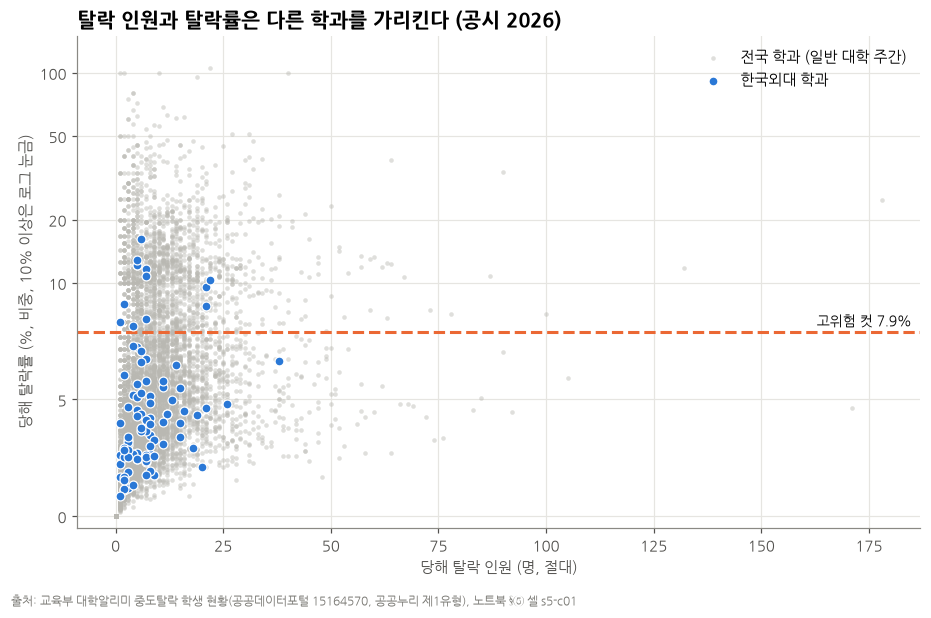

저장: figures/cand_c01_count_x_rate.png
그래서 무엇: 고위험(탈락률 ≥ 7.9%) 학과 중 453개는 탈락 인원 5명 이하 — 비율만 보면 작은 학과가, 인원만 보면 큰 학과가 앞에 선다(부록 E R1: 한국외대 교집합 0곳)


In [44]:
# s5-c01 [단독, 베스트 후보·필수 교차] 탈락 인원(명) × 탈락률(%) 산점도 — 분석 표본 t=2026, 한국외대 강조
te = TE.copy()
fig, ax = plt.subplots(figsize=(8.5, 5.6))
oth = te[~te['학교코드'].eq(HUFS_CODE)]
ax.scatter(oth['계'], oth['중도탈락학생비율'], s=9, color=GRAY, alpha=0.45, linewidths=0, label='전국 학과 (일반 대학 주간)')
hu = te[te['학교코드'].eq(HUFS_CODE)]
ax.scatter(hu['계'], hu['중도탈락학생비율'], s=34, color=C1, edgecolor='white', linewidth=0.8, label='한국외대 학과', zorder=3)
ax.axhline(CUT, color=C2, lw=2, ls='--')
ax.annotate(f'고위험 컷 {CUT:.1f}%', xy=(0.99, CUT), xycoords=('axes fraction', 'data'), xytext=(0, 4), textcoords='offset points', ha='right', fontsize=9, color=INK)
ax.set_yscale('symlog', linthresh=10); ax.set_ylim(-0.5, 150)
ax.yaxis.set_major_locator(FixedLocator([0, 5, 10, 20, 50, 100])); ax.yaxis.set_major_formatter(PLAIN); ax.yaxis.set_minor_locator(FixedLocator([]))
ax.set_xlabel('당해 탈락 인원 (명, 절대)'); ax.set_ylabel('당해 탈락률 (%, 비중, 10% 이상은 로그 눈금)')
ax.set_title('탈락 인원과 탈락률은 다른 학과를 가리킨다 (공시 2026)')
ax.legend(frameon=False, loc='upper right')
hi_rate_small = int(((te['중도탈락학생비율'] >= CUT) & (te['계'] <= 5)).sum())
finish(fig, 's5-c01', 'count_x_rate',
       f"고위험(탈락률 ≥ {CUT:.1f}%) 학과 중 {hi_rate_small}개는 탈락 인원 5명 이하 — 비율만 보면 작은 학과가, 인원만 보면 큰 학과가 앞에 선다(부록 E R1: 한국외대 교집합 0곳)")

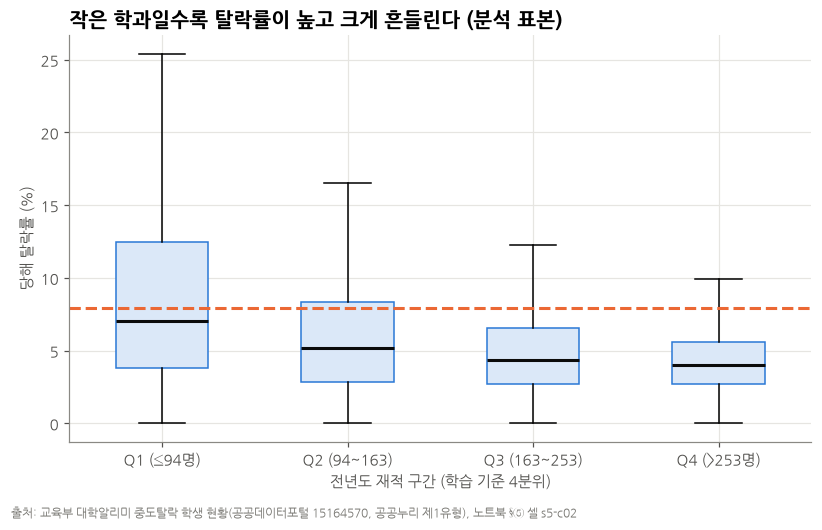

저장: figures/cand_c02_size_box.png
그래서 무엇: 사분위 범위(IQR)가 Q1 8.7%p → Q4 2.9%p — 소규모 학과는 비율이 크게 흔들려 최소 재적 기준(30명)과 인원 병기가 필요


In [45]:
# s5-c02 [단독] 전년도 재적 구간별 당해 탈락률 분포 — 소규모 학과의 비율 변동
fig, ax = plt.subplots(figsize=(7.5, 4.8))
groups = [M.loc[M['size_q'].eq(q), '중도탈락학생비율'] for q in ['Q1', 'Q2', 'Q3', 'Q4']]
bp = ax.boxplot(groups, widths=0.5, showfliers=False, patch_artist=True, medianprops={'color': INK, 'lw': 2})
for b_ in bp['boxes']:
    b_.set_facecolor('#dbe8f8'); b_.set_edgecolor(C1)
lab = [f'Q1 (≤{QB[0]:.0f}명)', f'Q2 ({QB[0]:.0f}~{QB[1]:.0f})', f'Q3 ({QB[1]:.0f}~{QB[2]:.0f})', f'Q4 (>{QB[2]:.0f}명)']
ax.set_xticks([1, 2, 3, 4], lab); ax.set_ylabel('당해 탈락률 (%)'); ax.set_xlabel('전년도 재적 구간 (학습 기준 4분위)')
ax.axhline(CUT, color=C2, lw=2, ls='--'); ax.set_title('작은 학과일수록 탈락률이 높고 크게 흔들린다 (분석 표본)')
iqr = [g.quantile(.75) - g.quantile(.25) for g in groups]
finish(fig, 's5-c02', 'size_box', f'사분위 범위(IQR)가 Q1 {iqr[0]:.1f}%p → Q4 {iqr[3]:.1f}%p — 소규모 학과는 비율이 크게 흔들려 최소 재적 기준(30명)과 인원 병기가 필요')

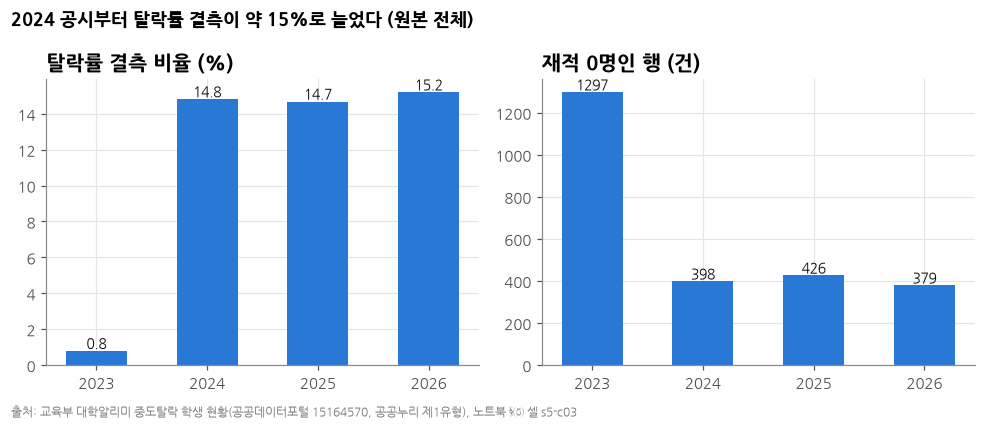

저장: figures/cand_c03_missing_year.png
그래서 무엇: 결측률 2023 0.8% → 2024~2026 약 15% — 공시 방식 변화로 보이며 결측은 보정하지 않고 표본에서 제외


In [46]:
# s5-c03 [서브플롯] 공시연도별 비율 결측률과 재적 0 건수 — 함정(공시 정의·결측 패턴 변화)
yy = df.groupby('공시연도').agg(결측률=('중도탈락학생비율', lambda v: v.isna().mean() * 100), 재적0=('재적학생', lambda v: v.eq(0).sum()))
fig, axs = plt.subplots(1, 2, figsize=(9, 3.8))
axs[0].bar(yy.index.astype(str), yy['결측률'], color=C1, width=0.55); axs[0].set_title('탈락률 결측 비율 (%)')
axs[1].bar(yy.index.astype(str), yy['재적0'], color=C1, width=0.55); axs[1].set_title('재적 0명인 행 (건)')
for a_, col in zip(axs, ['결측률', '재적0']):
    for x_, v_ in zip(yy.index.astype(str), yy[col]):
        a_.text(x_, v_, f'{v_:.1f}' if col == '결측률' else f'{int(v_)}', ha='center', va='bottom', fontsize=9, color=INK)
fig.suptitle('2024 공시부터 탈락률 결측이 약 15%로 늘었다 (원본 전체)', x=0.01, ha='left', fontweight='bold')
finish(fig, 's5-c03', 'missing_year', f"결측률 2023 {yy['결측률'].iloc[0]:.1f}% → 2024~2026 약 15% — 공시 방식 변화로 보이며 결측은 보정하지 않고 표본에서 제외")

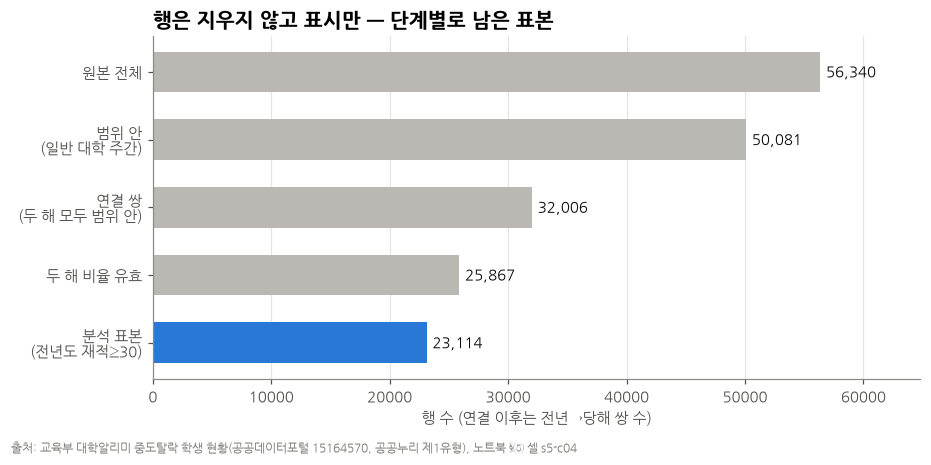

저장: figures/cand_c04_funnel.png
그래서 무엇: 원본 56,340행 중 분석 표본 23,114쌍 — 각 단계의 제외 사유와 건수는 정제로그 표 4·5


In [47]:
# s5-c04 [단독, 베스트 후보] 정제 추적: 원본 → 범위 → 연결 쌍 → 분석 표본 (행 수)
st = [('원본 전체', len(df_raw)), ('범위 안\n(일반 대학 주간)', int(df['in_scope'].sum())), ('연결 쌍\n(두 해 모두 범위 안)', n_link),
      ('두 해 비율 유효', int((pairs['both_in_scope'] & pairs['rate_ok'] & pairs['prev_rate_ok']).sum())), (f'분석 표본\n(전년도 재적≥{MIN_ENROLL})', len(sample))]
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ys = np.arange(len(st))[::-1]
ax.barh(ys, [v for _, v in st], color=[GRAY, GRAY, GRAY, GRAY, C1], height=0.6)
for y_, (n_, v_) in zip(ys, st):
    ax.text(v_ + 500, y_, f'{v_:,}', va='center', fontsize=10, color=INK)
ax.set_yticks(ys, [n_ for n_, _ in st]); ax.set_xlim(0, len(df_raw) * 1.15); ax.grid(axis='y', visible=False)
ax.set_xlabel('행 수 (연결 이후는 전년→당해 쌍 수)'); ax.set_title('행은 지우지 않고 표시만 — 단계별로 남은 표본')
finish(fig, 's5-c04', 'funnel', f'원본 {len(df_raw):,}행 중 분석 표본 {len(sample):,}쌍 — 각 단계의 제외 사유와 건수는 정제로그 표 4·5')

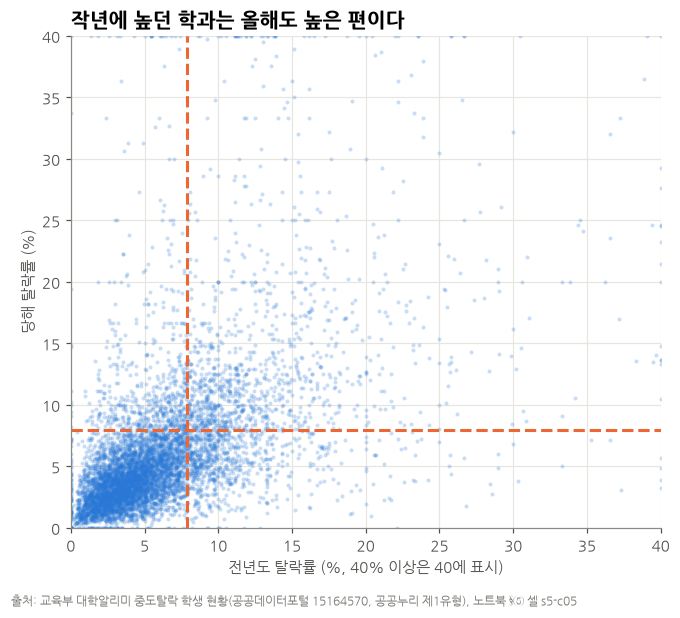

저장: figures/cand_c05_persistence.png
그래서 무엇: 작년 고위험 학과의 58.6%가 올해도 고위험(스피어만 0.62) — 그래서 "작년 명단 그대로"가 강한 기준선


In [48]:
# s5-c05 [단독, 베스트 후보] 전년도 탈락률 × 당해 탈락률 — 지속성(기준선 ②의 근거), 테스트 t=2026
fig, ax = plt.subplots(figsize=(6.2, 5.6))
ax.scatter(TE['prev_rate'].clip(upper=40), TE['중도탈락학생비율'].clip(upper=40), s=7, color=C1, alpha=0.25, linewidths=0)
ax.axvline(CUT, color=C2, lw=2, ls='--'); ax.axhline(CUT, color=C2, lw=2, ls='--')
ax.set_xlim(0, 40); ax.set_ylim(0, 40)
ax.set_xlabel('전년도 탈락률 (%, 40% 이상은 40에 표시)'); ax.set_ylabel('당해 탈락률 (%)')
stay = TE.loc[TE['prev_high'].eq(1), 'y'].mean() * 100
ax.set_title('작년에 높던 학과는 올해도 높은 편이다')
rho = TE['prev_rate'].corr(TE['중도탈락학생비율'], method='spearman')
finish(fig, 's5-c05', 'persistence', f'작년 고위험 학과의 {stay:.1f}%가 올해도 고위험(스피어만 {rho:.2f}) — 그래서 "작년 명단 그대로"가 강한 기준선')

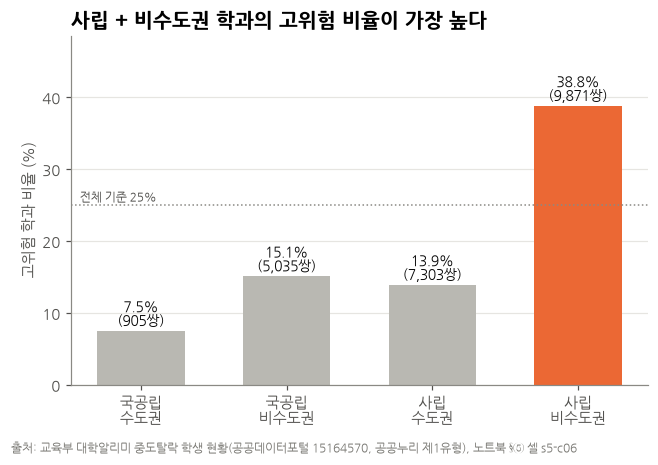

저장: figures/cand_c06_sector_region.png
그래서 무엇: 사립·비수도권 38.8% vs 국공립·수도권 7.5% — 두 요인이 겹치므로 회귀(s4-05)로 각각의 효과를 분리


In [49]:
# s5-c06 [단독] 설립유형 × 수도권 4칸 고위험 비율 (가설 A 기술통계)
fig, ax = plt.subplots(figsize=(6, 4.2))
cats = [('국공립', '수도권'), ('국공립', '비수도권'), ('사립', '수도권'), ('사립', '비수도권')]
vals = [four_pct.loc[a, b] for a, b in cats]; ns = [four_n.loc[a, b] for a, b in cats]
cols = [GRAY, GRAY, GRAY, C2]
xs = np.arange(4)
ax.bar(xs, vals, color=cols, width=0.6)
for x_, v_, n_ in zip(xs, vals, ns):
    ax.text(x_, v_ + 0.8, f'{v_:.1f}%\n({n_:,}쌍)', ha='center', fontsize=9, color=INK)
ax.set_xticks(xs, [f'{a}\n{b}' for a, b in cats]); ax.set_ylabel('고위험 학과 비율 (%)'); ax.set_ylim(0, max(vals) * 1.25)
ax.axhline(25, color='#8a8984', lw=1, ls=':'); ax.text(-0.42, 25.6, '전체 기준 25%', fontsize=8, color='#52514e', ha='left')
ax.set_title('사립 + 비수도권 학과의 고위험 비율이 가장 높다'); ax.grid(axis='x', visible=False)
finish(fig, 's5-c06', 'sector_region', f'사립·비수도권 {vals[3]:.1f}% vs 국공립·수도권 {vals[0]:.1f}% — 두 요인이 겹치므로 회귀(s4-05)로 각각의 효과를 분리')

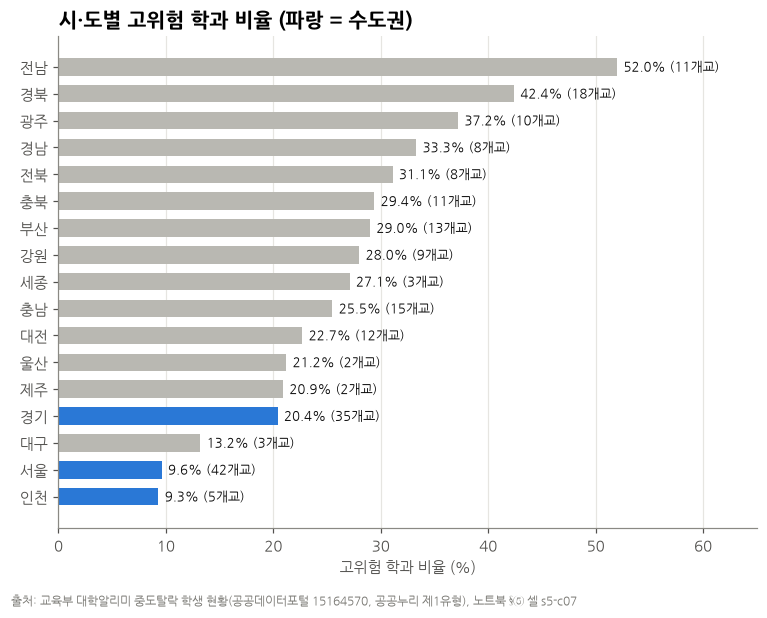

저장: figures/cand_c07_sido.png
그래서 무엇: 전남 52.0% ~ 인천 9.3% — 수도권 3곳이 하위권(학교 수가 적은 시·도는 해석 주의)


In [50]:
# s5-c07 [단독] 시·도별 고위험 비율 (가설 A 기술통계)
sd = sido.sort_values('고위험비율')
fig, ax = plt.subplots(figsize=(7, 5.6))
colors_ = [C1 if r in ('서울', '인천', '경기') else GRAY for r in sd.index]
ax.barh(sd.index, sd['고위험비율'], color=colors_, height=0.65)
for y_, (v_, n_) in enumerate(zip(sd['고위험비율'], sd['학교수'])):
    ax.text(v_ + 0.6, y_, f'{v_:.1f}% ({n_}개교)', va='center', fontsize=8.5, color=INK)
ax.set_xlabel('고위험 학과 비율 (%)'); ax.set_xlim(0, sd['고위험비율'].max() * 1.25); ax.grid(axis='y', visible=False)
ax.set_title('시·도별 고위험 학과 비율 (파랑 = 수도권)')
finish(fig, 's5-c07', 'sido', f"{sd.index[-1]} {sd['고위험비율'].iloc[-1]:.1f}% ~ {sd.index[0]} {sd['고위험비율'].iloc[0]:.1f}% — 수도권 3곳이 하위권(학교 수가 적은 시·도는 해석 주의)")

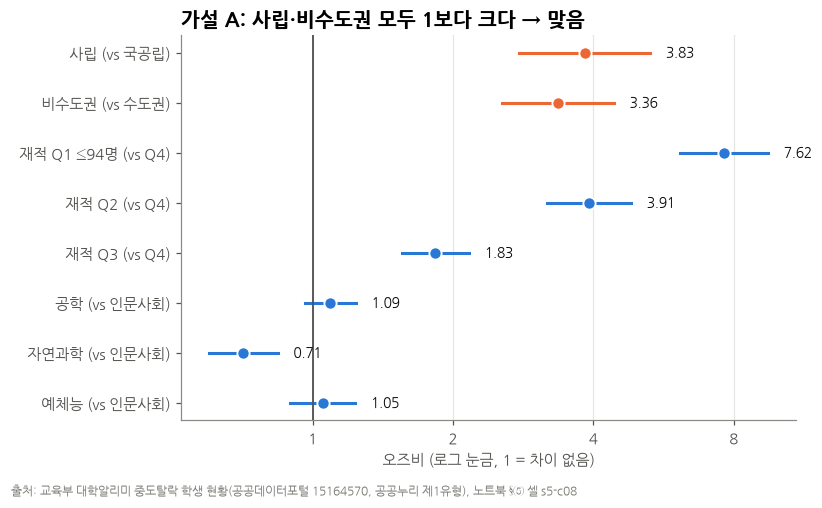

저장: figures/cand_c08_forest_A.png
그래서 무엇: 대계열·규모를 통제해도 사립 3.8배, 비수도권 3.4배 — 다만 소규모(Q1) 효과가 7.6배로 가장 크다


In [51]:
# s5-c08 [단독, 베스트 후보] 가설 A 오즈비 포레스트 플롯 (95% CI, 학교 군집 SE)
rows_ = [('사립 (vs 국공립)', 'priv'), ('비수도권 (vs 수도권)', 'nonmetro'),
         (f'재적 Q1 ≤{QB[0]:.0f}명 (vs Q4)', "C(size_q, Treatment('Q4'))[T.Q1]"), ('재적 Q2 (vs Q4)', "C(size_q, Treatment('Q4'))[T.Q2]"),
         ('재적 Q3 (vs Q4)', "C(size_q, Treatment('Q4'))[T.Q3]"), ('공학 (vs 인문사회)', "C(field, Treatment('인문사회계열'))[T.공학계열]"),
         ('자연과학 (vs 인문사회)', "C(field, Treatment('인문사회계열'))[T.자연과학계열]"), ('예체능 (vs 인문사회)', "C(field, Treatment('인문사회계열'))[T.예체능계열]")]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for i, (lab_, key) in enumerate(rows_[::-1]):
    o, lo_, hi_ = tabA.loc[key, ['오즈비', 'CI 하한', 'CI 상한']]
    c_ = C2 if key in ('priv', 'nonmetro') else C1
    ax.plot([lo_, hi_], [i, i], color=c_, lw=2); ax.plot(o, i, 'o', color=c_, ms=8, mec='white', mew=1.2)
    ax.text(hi_ * 1.08, i, f'{o:.2f}', va='center', fontsize=9, color=INK)
ax.axvline(1, color='#52514e', lw=1.2)
ax.set_xscale('log'); ax.xaxis.set_major_locator(FixedLocator([0.5, 1, 2, 4, 8])); ax.xaxis.set_major_formatter(PLAIN); ax.xaxis.set_minor_locator(FixedLocator([]))
ax.set_yticks(range(len(rows_)), [r[0] for r in rows_[::-1]]); ax.grid(axis='y', visible=False)
ax.set_xlabel('오즈비 (로그 눈금, 1 = 차이 없음)'); ax.set_title(f'가설 A: 사립·비수도권 모두 1보다 크다 → {verdict_A}')
finish(fig, 's5-c08', 'forest_A', f"대계열·규모를 통제해도 사립 {tabA.loc['priv', '오즈비']:.1f}배, 비수도권 {tabA.loc['nonmetro', '오즈비']:.1f}배 — 다만 소규모(Q1) 효과가 {tabA.loc[rows_[2][1], '오즈비']:.1f}배로 가장 크다")

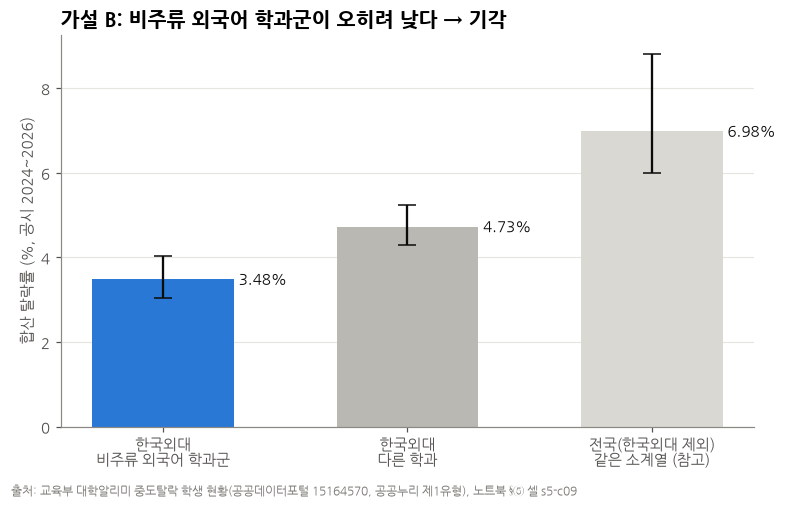

저장: figures/cand_c09_hufs_groups.png
그래서 무엇: 교내 다른 학과보다 1.25%p 낮고(구간 [-1.92, -0.56]), 전국 같은 소계열보다도 낮다 — 어문 학과군을 이탈 지원 우선 대상으로 볼 근거 없음 → '모집(입학처)' 관점으로 재정의


In [52]:
# s5-c09 [단독, 베스트 후보·필수 B] 한국외대 학과군별 2024~2026 합산 탈락률 + 학과코드 부트스트랩 95% 구간
def boot_one(d, n=2000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    g = d.groupby('학과코드')[['계', '재적학생']].sum().values
    s_ = np.array([g[rng.integers(0, len(g), len(g))].sum(0) for _ in range(n)])
    return np.percentile(s_[:, 0] / s_[:, 1] * 100, [2.5, 97.5])
grp = [('한국외대\n비주류 외국어 학과군', H[H['target']], C1), ('한국외대\n다른 학과', H[~H['target']], GRAY),
       ('전국(한국외대 제외)\n같은 소계열 (참고)', NAT, '#d9d8d3')]
fig, ax = plt.subplots(figsize=(7.2, 4.6))
for i, (lab_, d_, c_) in enumerate(grp):
    v_ = pooled(d_); lo_, hi_ = boot_one(d_)
    ax.bar(i, v_, color=c_, width=0.58)
    ax.errorbar(i, v_, yerr=[[v_ - lo_], [hi_ - v_]], color=INK, capsize=6, lw=1.5)
    ax.text(i + 0.31, v_, f'{v_:.2f}%', va='center', fontsize=10, color=INK)
ax.set_xticks(range(3), [g_[0] for g_ in grp]); ax.set_ylabel('합산 탈락률 (%, 공시 2024~2026)'); ax.grid(axis='x', visible=False)
ax.set_title(f'가설 B: 비주류 외국어 학과군이 오히려 낮다 → {verdict_B}')
finish(fig, 's5-c09', 'hufs_groups', f"교내 다른 학과보다 {abs(resB['차이(%p)']):.2f}%p 낮고(구간 [{resB['95% 하한']:.2f}, {resB['95% 상한']:.2f}]), 전국 같은 소계열보다도 낮다 — 어문 학과군을 이탈 지원 우선 대상으로 볼 근거 없음 → '모집(입학처)' 관점으로 재정의")

그림에서 뺀 비율 해석 불가 단위: 19개 (연평균 재적 30명 미만, 근거 sE-02) — 행과 인원 순위는 그대로


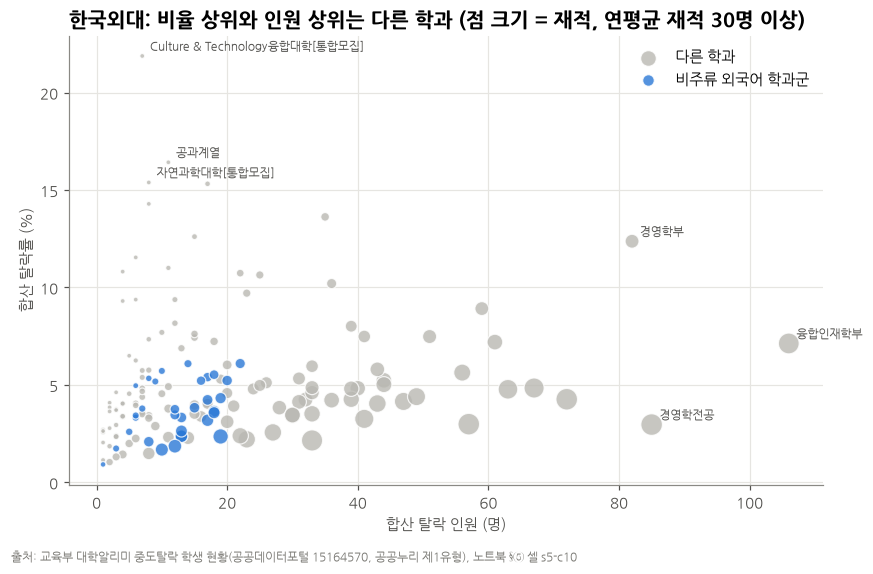

저장: figures/cand_c10_hufs_count_rate.png
그래서 무엇: 해석 가능한 단위만 봐도 비율 상위 10과 인원 상위 10의 교집합 1곳 — 비율과 인원은 다른 학과를 가리킨다(원판정 sE-01, 보정 sE-02)


In [53]:
# s5-c10 [단독] 한국외대 학과별 인원(명) × 비율(%) — 2024~2026 합산, 비주류 외국어 학과군 강조
r1p = H.groupby('학과코드').agg(탈락합=('계', 'sum'), 재적합=('재적학생', 'sum'), 대상=('target', 'max'), 학과명=('학과명', 'last'), 연수=('공시연도', 'nunique'))
r1p['비율'] = r1p['탈락합'] / r1p['재적합'] * 100
# 비율 해석 불가: 연평균 재적 < MIN_ENROLL(30명) — '재적 1명 · 탈락 1명 = 100%' 같은 개편 · 신설 단위 (근거는 부록 E 셀 sE-02)
r1p['해석불가'] = r1p['재적합'] / r1p['연수'] < MIN_ENROLL
ok_r = r1p[~r1p['해석불가']]
fig, ax = plt.subplots(figsize=(8, 5.2))
for flag, c_, lab_ in [(False, GRAY, '다른 학과'), (True, C1, '비주류 외국어 학과군')]:
    d_ = ok_r[ok_r['대상'].eq(flag)]
    ax.scatter(d_['탈락합'], d_['비율'], s=np.clip(d_['재적합'] / 8, 10, 200), color=c_, alpha=0.8, edgecolor='white', linewidth=0.8, label=lab_)
lab_pts = pd.concat([ok_r.nlargest(3, '탈락합'), ok_r.nlargest(3, '비율')]).drop_duplicates(subset=['탈락합', '비율'])
for _, r_ in lab_pts.iterrows():
    ax.annotate(r_['학과명'], (r_['탈락합'], r_['비율']), xytext=(5, 4), textcoords='offset points', fontsize=8, color='#52514e')
ax.set_xlabel('합산 탈락 인원 (명)'); ax.set_ylabel('합산 탈락률 (%)')
ax.set_title(f"한국외대: 비율 상위와 인원 상위는 다른 학과 (점 크기 = 재적, 연평균 재적 {MIN_ENROLL}명 이상)"); ax.legend(frameon=False)
inter10 = set(ok_r.sort_values(['비율', '탈락합'], ascending=False).head(10).index) & set(r1p.sort_values(['탈락합', '비율'], ascending=False).head(10).index)
print(f"그림에서 뺀 비율 해석 불가 단위: {int(r1p['해석불가'].sum())}개 (연평균 재적 {MIN_ENROLL}명 미만, 근거 sE-02) — 행과 인원 순위는 그대로")
finish(fig, 's5-c10', 'hufs_count_rate', f"해석 가능한 단위만 봐도 비율 상위 10과 인원 상위 10의 교집합 {len(inter10)}곳 — 비율과 인원은 다른 학과를 가리킨다(원판정 sE-01, 보정 sE-02)")

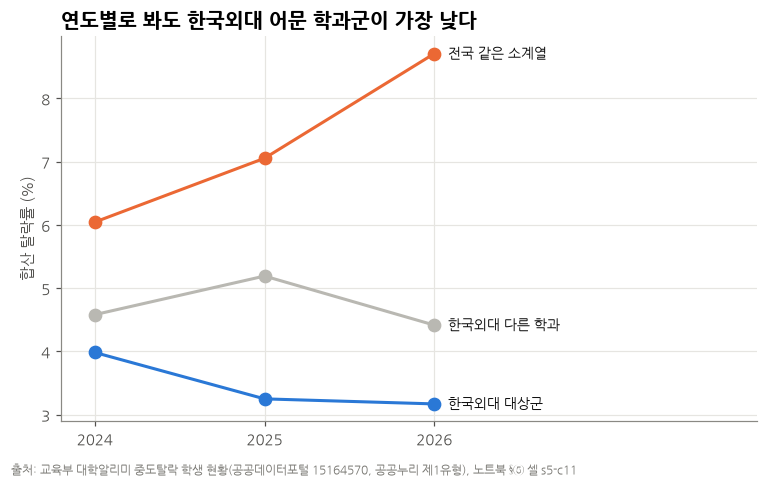

저장: figures/cand_c11_hufs_vs_nat_year.png
그래서 무엇: 3개 연도 중 3개 연도에서 한국외대 대상군 < 교내 다른 학과 < 전국 같은 소계열 — 결론이 특정 해에만 의존하는지 확인


In [54]:
# s5-c11 [단독] 한국외대 대상군 vs 전국 같은 소계열 — 연도별 합산 비율 (B 참고 해석)
yr = pd.DataFrame({'한국외대 대상군': HT.groupby('공시연도').apply(pooled, include_groups=False),
                   '전국 같은 소계열': NAT.groupby('공시연도').apply(pooled, include_groups=False),
                   '한국외대 다른 학과': H[~H['target']].groupby('공시연도').apply(pooled, include_groups=False)})
fig, ax = plt.subplots(figsize=(7, 4.4))
for col, c_ in zip(yr.columns, [C1, C2, GRAY]):
    ax.plot(yr.index.astype(str), yr[col], marker='o', ms=8, lw=2, color=c_)
    ax.text(len(yr) - 1 + 0.08, yr[col].iloc[-1], col, va='center', fontsize=9, color=INK)
ax.set_ylabel('합산 탈락률 (%)'); ax.set_xlim(-0.2, len(yr) + 0.9); ax.set_title('연도별로 봐도 한국외대 어문 학과군이 가장 낮다')
order_ok = int(((yr['한국외대 대상군'] < yr['한국외대 다른 학과']) & (yr['한국외대 다른 학과'] < yr['전국 같은 소계열'])).sum())
finish(fig, 's5-c11', 'hufs_vs_nat_year', f'3개 연도 중 {order_ok}개 연도에서 한국외대 대상군 < 교내 다른 학과 < 전국 같은 소계열 — 결론이 특정 해에만 의존하는지 확인')

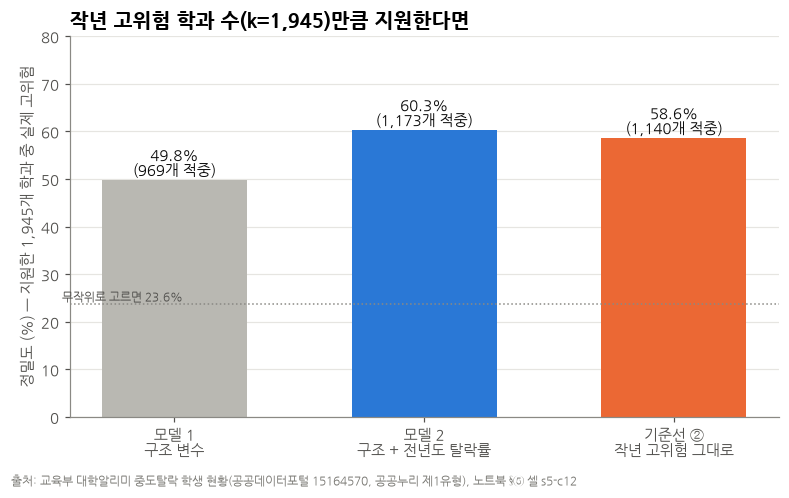

저장: figures/cand_c12_model_vs_baseline.png
그래서 무엇: 모델 2가 작년 명단보다 +1.7%p(적중 +33개) — 개선은 작고, 구조 정보만으로는 작년 명단보다 못하다


In [55]:
# s5-c12 [단독, 베스트 후보·필수 예측] 같은 k에서 모델 vs 기준선 정밀도 (테스트 t=2026)
ev = EVAL.iloc[:3].copy()
labs = ['모델 1\n구조 변수', '모델 2\n구조 + 전년도 탈락률', '기준선 ②\n작년 고위험 그대로']
fig, ax = plt.subplots(figsize=(7.2, 4.5))
cols = [GRAY, C1, C2]
ax.bar(range(3), ev['정밀도(%)'], color=cols, width=0.58)
for i, (p_, h_) in enumerate(zip(ev['정밀도(%)'], ev['맞힌 학과 수'])):
    ax.text(i, p_ + 1, f'{p_:.1f}%\n({int(h_):,}개 적중)', ha='center', fontsize=9.5, color=INK)
ax.axhline(TE['y'].mean() * 100, color='#8a8984', lw=1, ls=':'); ax.text(-0.45, TE['y'].mean() * 100 + 0.8, f"무작위로 고르면 {TE['y'].mean() * 100:.1f}%", fontsize=8, ha='left', color='#52514e')
ax.set_xticks(range(3), labs); ax.set_ylabel(f'정밀도 (%) — 지원한 {K:,}개 학과 중 실제 고위험'); ax.set_ylim(0, 80); ax.grid(axis='x', visible=False)
ax.set_title(f'작년 고위험 학과 수(k={K:,})만큼 지원한다면')
finish(fig, 's5-c12', 'model_vs_baseline', f"모델 2가 작년 명단보다 {EVAL.loc[1, '정밀도(%)'] - EVAL.loc[2, '정밀도(%)']:+.1f}%p(적중 {int(EVAL.loc[1, '맞힌 학과 수'] - EVAL.loc[2, '맞힌 학과 수']):+d}개) — 개선은 작고, 구조 정보만으로는 작년 명단보다 못하다")

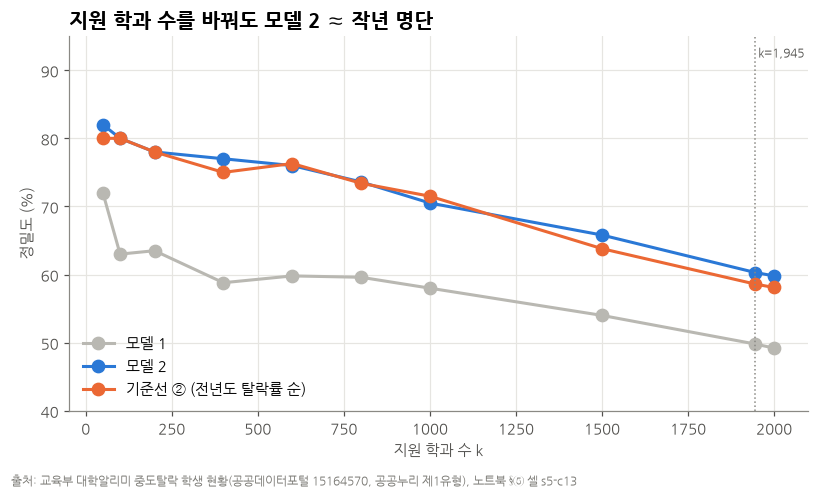

저장: figures/cand_c13_k_curve.png
그래서 무엇: 적게 지원할수록 정밀도는 높지만, 어떤 k에서도 모델 2와 작년 명단의 차이는 ±2%p 안팎 — 결론이 k 선택에 좌우되지 않음


In [56]:
# s5-c13 [단독, 베스트 후보] k(지원 학과 수)에 따른 정밀도 — 모델 vs 기준선 ②
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for col, c_ in [('모델 1', GRAY), ('모델 2', C1), ('기준선 ② (전년도 탈락률 순)', C2)]:
    ax.plot(KCURVE['k'], KCURVE[col], marker='o', ms=8, lw=2, color=c_, label=col)
ax.axvline(K, color='#8a8984', lw=1, ls=':'); ax.text(K, 92, f' k={K:,}', fontsize=8, color='#52514e')
ax.set_xlabel('지원 학과 수 k'); ax.set_ylabel('정밀도 (%)'); ax.set_ylim(40, 95); ax.legend(frameon=False, loc='lower left')
ax.set_title('지원 학과 수를 바꿔도 모델 2 ≈ 작년 명단')
finish(fig, 's5-c13', 'k_curve', '적게 지원할수록 정밀도는 높지만, 어떤 k에서도 모델 2와 작년 명단의 차이는 ±2%p 안팎 — 결론이 k 선택에 좌우되지 않음')

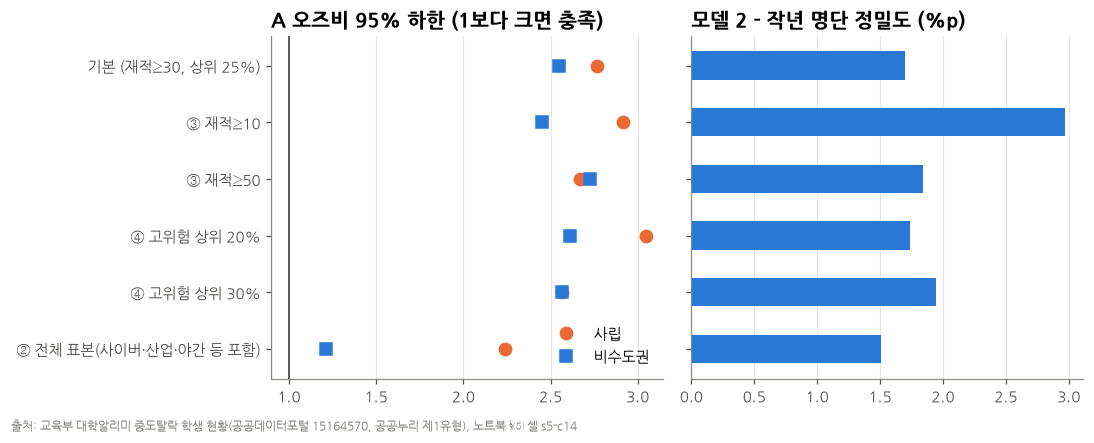

저장: figures/cand_c14_sensitivity.png
그래서 무엇: 6개 조건 모두 A 맞음(하한 > 1), 모델 2가 작년 명단보다 +1.5~3%p — 결론이 기준 선택에 뒤집히지 않음


In [57]:
# s5-c14 [단독] 민감도 요약 — 조건별 사립·비수도권 오즈비 하한과 정밀도 차이
sv = SENS_T.copy()
sv['정밀도 차이'] = sv['모델2 정밀도'].astype(float) - sv['기준선② 정밀도'].astype(float)
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
ys = np.arange(len(sv))[::-1]
axs[0].plot(sv['사립 CI하한'].astype(float), ys, 'o', ms=8, color=C2, label='사립')
axs[0].plot(sv['비수도권 CI하한'].astype(float), ys, 's', ms=8, color=C1, label='비수도권')
axs[0].axvline(1, color='#52514e', lw=1.2); axs[0].set_title('A 오즈비 95% 하한 (1보다 크면 충족)'); axs[0].legend(frameon=False)
axs[0].set_yticks(ys, sv.index)
axs[1].barh(ys, sv['정밀도 차이'], color=C1, height=0.5); axs[1].axvline(0, color='#52514e', lw=1.2)
axs[1].set_title('모델 2 - 작년 명단 정밀도 (%p)')
for a_ in axs:
    a_.grid(axis='y', visible=False)
finish(fig, 's5-c14', 'sensitivity', '6개 조건 모두 A 맞음(하한 > 1), 모델 2가 작년 명단보다 +1.5~3%p — 결론이 기준 선택에 뒤집히지 않음')

### ⑤-2 베스트 3종 선택 (후보 14개를 모두 그린 뒤 작성, 2026-11-11)
점수: 각 기준 1~3점 (3 = 가장 좋음). ① 의사결정(어느 학과에 지원할까)에 직접 답함 ② 가설 A·B·예측 절과 연결 ③ '그래서 무엇'이 바로 나옴 ④ 안내문 요건(교차=산점도, 장식 금지) ⑤ 10분 안에 설명 가능

| 후보 | 내용 | ① | ② | ③ | ④ | ⑤ | 합계 | 선택 | 선택·탈락 이유 |
|---|---|---|---|---|---|---|---|---|---|
| s5-c10 | 한국외대 인원×비율 산점도 | 3 | 3 | 3 | 3 | 3 | **15** | **필수 ① 교차** | 의사결정자(한국외대)의 학과가 직접 보이고, 비주류 외국어 학과군(파랑)이 낮은 쪽에 몰린 것(B)과, 개편 · 신설 단위를 빼고도 비율 상위와 인원 상위가 다른 것(R1 보정판)이 한 장에 드러남 |
| s5-c01 | 전국 인원×비율 산점도 | 2 | 2 | 3 | 3 | 2 | 12 | 부록 | 전국 맥락은 좋지만 점 7,500개라 한국외대 판단이 흐려짐 → c10에 밀림 |
| s5-c09 | 한국외대 학과군 비교 + 95% 구간 | 3 | 3 | 3 | 3 | 3 | **15** | **필수 ② 가설 B** | 판정(기각)과 그 근거(구간)가 한눈에, 전국 참고 막대까지 B 참고 해석을 같이 보여 줌 |
| s5-c11 | 연도별 B 비교 선 | 2 | 3 | 2 | 2 | 2 | 11 | 부록 | 3개 연도 모두 같은 순서 — 견고성 근거로 부록 |
| s5-c12 | 같은 k 정밀도 막대 | 3 | 3 | 3 | 3 | 3 | **15** | **필수 ③ 예측** | "작년 명단만큼 지원한다면" 한 문장으로 설명되고, 무작위 기준선(23.6%)까지 들어가 청중이 크기를 바로 읽음 |
| s5-c13 | k에 따른 정밀도 곡선 | 2 | 3 | 2 | 3 | 2 | 12 | 부록(민감도 ⑤) | k 선택에 결론이 좌우되지 않음을 보여 주지만 설명 시간이 듦 |
| s5-c08 | 가설 A 오즈비 포레스트 | 2 | 3 | 3 | 3 | 2 | 13 | 본문 보조(슬라이드 6) | 가설 A 판정 슬라이드의 근거 그림. 필수 3종 밖이지만 판정 슬라이드에 사용 |
| s5-c04 | 정제 추적 퍼널 | 1 | 1 | 2 | 3 | 3 | 10 | 본문 보조(슬라이드 4) | 정제 단계 설명용 |
| s5-c06 | 설립×수도권 4칸 막대 | 2 | 3 | 3 | 2 | 3 | 13 | 부록 | c08과 같은 메시지(기술통계), 회귀가 더 엄밀 |
| s5-c05 | 전년도×당해 산점도 | 2 | 2 | 3 | 3 | 2 | 12 | 부록 | 기준선 ②가 강한 이유(지속성) 설명용 |
| s5-c02 | 재적 구간별 상자그림 | 1 | 2 | 2 | 2 | 2 | 9 | 부록 | 최소 재적 30명 근거 |
| s5-c03 | 연도별 결측률 | 1 | 1 | 2 | 2 | 3 | 9 | 부록·슬라이드 3 보조 | 함정 설명용 |
| s5-c07 | 시·도별 고위험 비율 | 1 | 2 | 2 | 2 | 2 | 9 | 부록 | 학교 수가 적은 시·도는 해석이 불안정 |
| s5-c14 | 민감도 요약 | 1 | 3 | 2 | 2 | 1 | 9 | 부록 D | 결론이 뒤집히지 않는다는 근거 표의 그림판 |

선택한 3종은 아래 셀(s5-sel)이 `figures/fig1_scatter.png`, `fig2_hufs_groups.png`, `fig3_model_vs_baseline.png`로 다시 저장한다(보고서 `make_report.js`가 이 이름을 읽음).

In [58]:
# s5-sel ⑤-2 베스트 3종 선택 결과 → 보고서·슬라이드용 파일 이름으로 저장
# [출처 규칙] '(출처: 노트북 §⑤ 셀 s5-sel)' — 점수는 아래 마크다운 표(⑤-2)의 팀 기준
import shutil
BEST = {'fig1_scatter.png': 'cand_c10_hufs_count_rate.png',        # 필수 ① 교차 산점도
        'fig2_hufs_groups.png': 'cand_c09_hufs_groups.png',         # 필수 ② 가설 B 비교
        'fig3_model_vs_baseline.png': 'cand_c12_model_vs_baseline.png'}  # 필수 ③ 모델 vs 기준선
for dst, src in BEST.items():
    shutil.copyfile(f'{FIG_DIR}/{src}', f'{FIG_DIR}/{dst}')
    print(f'{dst:<28} ← {src}')
print('\n그래서 무엇 (슬라이드에 그대로 옮김):')
for cid in ['s5-c10', 's5-c09', 's5-c12']:
    print(f'- {cid}: {SO_WHAT[cid]}')

fig1_scatter.png             ← cand_c10_hufs_count_rate.png
fig2_hufs_groups.png         ← cand_c09_hufs_groups.png
fig3_model_vs_baseline.png   ← cand_c12_model_vs_baseline.png

그래서 무엇 (슬라이드에 그대로 옮김):
- s5-c10: 해석 가능한 단위만 봐도 비율 상위 10과 인원 상위 10의 교집합 1곳 — 비율과 인원은 다른 학과를 가리킨다(원판정 sE-01, 보정 sE-02)
- s5-c09: 교내 다른 학과보다 1.25%p 낮고(구간 [-1.92, -0.56]), 전국 같은 소계열보다도 낮다 — 어문 학과군을 이탈 지원 우선 대상으로 볼 근거 없음 → '모집(입학처)' 관점으로 재정의
- s5-c12: 모델 2가 작년 명단보다 +1.7%p(적중 +33개) — 개선은 작고, 구조 정보만으로는 작년 명단보다 못하다


### 권고·근거 (결과 확인 후 작성, 2026-11-12)
| 가설 | 판정 | 근거 수치 (셀) | 권고 |
|---|---|---|---|
| A 전국 구조 | **맞음** | 사립 OR 3.83 [2.77, 5.30], 비수도권 OR 3.36 [2.55, 4.43] (s4-05) | 전국 맥락으로만 사용. 한국외대 안에서는 모든 학과가 같은 설립유형 · 지역이라 배분 기준이 되지 못함 |
| A 예측 절 | 보고 | k = 1,945: 모델 2 60.3% vs 작년 명단 58.6%, +1.7%p · 적중 +33곳 (s4-07) | ① 내년 지원 명단은 작년 고위험 학과로 시작하고 모델 점수로 보완. 재적 30명 이상에서 고르고 탈락 인원(명)을 함께 표시(R1, sE-01 · sE-02) |
| B 한국외대 | **틀림(기각)** | 비주류 외국어 학과군 3.48% vs 교내 4.73%, −1.25%p [−1.92, −0.56], 3개 연도 모두 낮음 (s4-10 · s4-12b) | ③ 어문 학과군은 이탈이 아니라 '모집(입학처)' 관점으로 재정의 → 지원율 · 충원율 자료로 다음 분석 |
| B 예측 절 · 해석 | 보조 참고 | 2027 후보 상위 20곳 중 13곳이 1학년 단위, 탈락의 97.4%가 자퇴. 1학년만 모인 단위라 비율 직접 비교는 불가(다른 학과 1학년 3.9~15.5%) (s4-13 · s4-13b · s4-13c) | ② 1학년 초기 이탈 관리: 통합모집 · 계열 · 자유전공 단위부터 1학기 적응 상담과 전공 안내를 앞당김 |

**반대 결과 수용 (가설 B)**: ① 이탈이 1학년 단위로 옮겨 감(데이터로 일부 확인, 2026 공시부터라 부분 설명) ② 스스로 고른 전공(추정) ③ 이중전공 · 전과로 떠나지 않고 길을 바꿈(추정, `[확인 필요]`) — s4-12b

### 한계 (빠뜨리면 감점)
1. 테스트는 공시 2026 한 해뿐이다.
2. 학과 단위 집계라 개인 이탈 요인을 담지 못하며, 결과는 상관이지 인과가 아니다(A의 오즈비는 연관).
3. 폐지·통폐합·신설 학과가 연결에서 빠지는 생존 편향(미연결 5,399행, 한국외대 61개), 공시 정의·결측 패턴 변화.
- 추가: 표준분류는 학교별 신고에 의존해 같은 이름의 학과가 학교마다 다르게 분류될 수 있다. 우리는 학과를 재분류하지 않고 데이터가 준 분류를 그대로 쓴다. / "비인기"·"존폐 위기"는 판단 불가 / 캠퍼스 미구분 / 전국 비교군 소표본 / 학부·전공 이중 계상 가능성 `[확인 필요]`

### 믿기 어려운 이유 · 말할 수 없는 것
- 한국외대만 따로 검증하면 학과 94개, k = 16이라 우연에 크게 흔들린다(모델 2 37.5% vs 작년 명단 43.8%, s4-13).
- 1학년 단위의 탈락률은 다른 학과와 비율로 직접 비교할 수 없다(학년별 탈락 자료 없음, s4-13c).
- '재적 1명 · 탈락 1명 = 100%' 같은 개편 · 신설 단위의 비율은 위험을 뜻하지 않는다(19개, sE-02). 개편 이력은 `[확인 필요]`.
- 반수 · 자발적 지망 · 이중전공 같은 개인 사유는 데이터에 없어 추정으로만 말한다.
- 그래도 기준 6가지를 바꿔도 A · B 판정과 '모델 ≈ 작년 명단' 결론은 뒤집히지 않았다(s4-14).

## 부록 A. 재현성 확인
- **무엇을**: 런타임 재시작 후 처음부터 모두 실행해 핵심 수치를 한 셀에 모아 출력한다.
- **왜**: 다른 계정에서 돌려도 같은 숫자가 나와야 한다(안내문 마지막 점검).
- **초안 담당자**: `[팀 입력]` · **검토자**: `[팀 입력]` (`logs/기여도표.md`와 일치)
- **이 단계의 검증 흔적**: `logs/재현성_확인표.md`의 항목과 같은 이름으로 출력, 값이 다르면 '발견'으로 기록

In [59]:
# sA-01 재현성 요약
# [출처 규칙] 이 셀의 수치를 보고서·발표에 옮길 때 '(출처: 노트북 §부록 A 셀 sA-01)'를 붙인다.
# TODO: 원본 행×열, 범위 안 행 수, 분석 표본(학습/테스트), A 오즈비, B 차이·구간, 같은 k 정밀도, AUC, 기준선 ②, 실행 일시, 라이브러리 버전

## 부록 E. 보조 분석 R1 (인원×비율 착시, 가설 판정 아님)
- **무엇을**: 한국외대에서 탈락 비율(%) 상위 10 학과와 탈락 인원(명) 상위 10 학과의 교집합 수를 센다(공시 2024~2026 합산).
- **왜**: 프로젝트1의 절대×비중 교훈: 비율만 보고 지원하면 큰 학과의 이탈 인원을 놓칠 수 있다.
- **초안 담당자**: `[팀 입력]` · **검토자**: `[팀 입력]` (`logs/기여도표.md`와 일치)
- **이 단계의 검증 흔적**: `00_문제정의_가설.md` 10절 규칙(교집합 < 5) 그대로, 두 목록과 교집합 출력

In [60]:
# sE-01 R1 두 상위 10 목록과 교집합 (한국외대, 공시 2024~2026 합산, 학과코드 단위)
# [출처 규칙] '(출처: 노트북 §부록 E 셀 sE-01)'
r1 = H.groupby('학과코드').agg(학과명=('학과명', 'last'), 탈락합=('계', 'sum'), 재적합=('재적학생', 'sum'))
r1['합산 비율(%)'] = r1['탈락합'] / r1['재적합'] * 100
top_rate = r1.sort_values(['합산 비율(%)', '탈락합'], ascending=False).head(10)
top_cnt = r1.sort_values(['탈락합', '합산 비율(%)'], ascending=False).head(10)
inter = sorted(set(top_rate.index) & set(top_cnt.index))
print('비율 상위 10:'); display(top_rate.round(2))
print('인원 상위 10:'); display(top_cnt.round(2))
print(f'교집합 {len(inter)}곳:', r1.loc[inter, '학과명'].tolist())
print('▶ R1(부록):', '맞음 — 비율 하나로 우선순위를 정하면 안 되고 인원·비율을 함께 본다' if len(inter) < 5
      else '교집합 ≥ 5 — 비율 순위와 인원 순위가 대체로 같다')

비율 상위 10:


,학과명,탈락합,재적합,합산 비율(%)
학과코드,,,,
230906,일본어학전공,1.0,1,100.00
230908,일본문학전공,1.0,1,100.00
208236,컴퓨터공학과,1.0,2,50.00
205949,영어전공,2.0,5,40.00
12515,프랑스어과,6.0,19,31.58
244300,Finance & AI융합전공,13.0,54,24.07
249628,Culture & Technology융합대학[통합모집],7.0,32,21.88
249634,공과계열,11.0,67,16.42
249679,자연과학대학[통합모집],8.0,52,15.38


인원 상위 10:


,학과명,탈락합,재적합,합산 비율(%)
학과코드,,,,
233816,융합인재학부,106.0,1488,7.12
212090,경영학전공,85.0,2870,2.96
212091,경영학부,82.0,663,12.37
13127,독일어과,72.0,1690,4.26
212100,영미문학.문화학과,67.0,1385,4.84
230931,ELLT학과,63.0,1320,4.77
208231,화학과,61.0,848,7.19
208211,전자물리학과,59.0,662,8.91
19317,스페인어과,57.0,1911,2.98


교집합 0곳: []
▶ R1(부록): 맞음 — 비율 하나로 우선순위를 정하면 안 되고 인원·비율을 함께 본다


In [61]:
# sE-02 R1 해석 보정판: 비율을 해석할 수 없는 단위를 근거와 함께 표시하고, 같은 규칙으로 다시 센다 (원판정 sE-01은 그대로 둔다)
# [출처 규칙] '(출처: 노트북 §부록 E 셀 sE-02)'
# 왜: 원판정의 탈락률 상위에 '재적 1명 · 탈락 1명(100%)' 같은 단위가 올랐다. 재적(학년도 학적 보유자)과 탈락(그 1년 동안 떠난 수)은
#     같은 사람을 세므로 1/1 = 남아 있던 한 명이 떠났다는 뜻이다. 이런 단위는 비율이 학과의 위험이 아니라 개편 과정을 반영한다.
# 규칙(사전 고정 설계의 최소 재적 30명과 같은 기준): 공시 2024~2026 연평균 재적 < 30명이면 '비율 해석 불가'로 표시하고 비율 순위에서만 뺀다.
#     인원 순위에는 그대로 둔다(인원은 규모와 무관하게 의미가 있다). 행은 지우지 않는다.
allH = df[df['in_scope'] & df['학교코드'].eq(HUFS_CODE)]
life = allH.groupby('학과코드').agg(첫공시=('공시연도', 'min'), 끝공시=('공시연도', 'max'))
r1x = r1.join(life)
r1x['공시연수'] = H.groupby('학과코드')['공시연도'].nunique()
r1x['연평균재적'] = r1x['재적합'] / r1x['공시연수']
yearly = allH.pivot_table(index='학과코드', columns='공시연도', values='재적학생', aggfunc='sum')
mirb = H.groupby('학과코드')[['미복학', '계']].sum()
def why(code, r):
    if r['연평균재적'] >= MIN_ENROLL:
        return ''
    if r['끝공시'] < 2026 or (yearly.loc[code].dropna().iloc[-1] <= 5 and yearly.loc[code].dropna().iloc[0] > yearly.loc[code].dropna().iloc[-1]):
        share = mirb.loc[code, '미복학'] / mirb.loc[code, '계'] * 100 if mirb.loc[code, '계'] > 0 else np.nan
        return f'개편 전 잔류 추정(재적 감소·소멸, 미복학 {share:.0f}%)' if share == share else '개편 전 잔류 추정(재적 감소·소멸)'
    if r['첫공시'] >= 2024:
        return '신설·개편 초기 추정(첫 공시 이후 재적이 적음)'
    return '소규모 단위(연평균 재적 < 30명)'
r1x['해석'] = [why(c, r) for c, r in r1x.iterrows()]
flag = r1x['해석'].ne('')
print(f'비율 해석 불가로 표시한 단위: {int(flag.sum())}개 (한국외대 학과코드 {len(r1x)}개 중) — 이 중 원판정 탈락률 상위 10에 든 것: {int(flag.loc[top_rate.index].sum())}개')
display(r1x.loc[top_rate.index, ['학과명', '탈락합', '재적합', '합산 비율(%)', '연평균재적', '해석']].round(2))
top_rate_adj = r1x[~flag].sort_values(['합산 비율(%)', '탈락합'], ascending=False).head(10)
inter_adj = sorted(set(top_rate_adj.index) & set(top_cnt.index))
print('\n해석 보정판 탈락률 상위 10 (연평균 재적 ≥ 30명):'); display(top_rate_adj[['학과명', '탈락합', '재적합', '합산 비율(%)', '연평균재적']].round(2))
print(f'해석 보정판 교집합 {len(inter_adj)}곳:', r1x.loc[inter_adj, '학과명'].tolist())
print('▶ 원판정(사전 규칙):', f'교집합 {len(inter)}곳', '/ 해석 보정판:', f'교집합 {len(inter_adj)}곳',
      '→', '보정 뒤에도 5곳 미만 — 비율과 인원은 다른 학과를 가리킨다는 결론 유지' if len(inter_adj) < 5 else '보정 뒤에는 5곳 이상 — 착시의 상당 부분은 개편 단위 때문')

비율 해석 불가로 표시한 단위: 19개 (한국외대 학과코드 174개 중) — 이 중 원판정 탈락률 상위 10에 든 것: 6개


,학과명,탈락합,재적합,합산 비율(%),연평균재적,해석
학과코드,,,,,,
230906,일본어학전공,1.0,1,100.00,1.0,"개편 전 잔류 추정(재적 감소·소멸, 미복학 100%)"
230908,일본문학전공,1.0,1,100.00,1.0,"개편 전 잔류 추정(재적 감소·소멸, 미복학 100%)"
208236,컴퓨터공학과,1.0,2,50.00,2.0,"개편 전 잔류 추정(재적 감소·소멸, 미복학 100%)"
205949,영어전공,2.0,5,40.00,2.5,"개편 전 잔류 추정(재적 감소·소멸, 미복학 100%)"
12515,프랑스어과,6.0,19,31.58,9.5,"개편 전 잔류 추정(재적 감소·소멸, 미복학 83%)"
244300,Finance & AI융합전공,13.0,54,24.07,27.0,신설·개편 초기 추정(첫 공시 이후 재적이 적음)
249628,Culture & Technology융합대학[통합모집],7.0,32,21.88,32.0,
249634,공과계열,11.0,67,16.42,67.0,
249679,자연과학대학[통합모집],8.0,52,15.38,52.0,



해석 보정판 탈락률 상위 10 (연평균 재적 ≥ 30명):


,학과명,탈락합,재적합,합산 비율(%),연평균재적
학과코드,,,,,
249628,Culture & Technology융합대학[통합모집],7.0,32,21.88,32.00
249634,공과계열,11.0,67,16.42,67.00
249679,자연과학대학[통합모집],8.0,52,15.38,52.00
244314,Language & AI융합학부,17.0,111,15.32,55.50
249690,핵심외국어계열,8.0,56,14.29,56.00
249617,자유전공학부(글로벌),35.0,257,13.62,257.00
205954,Language & Diplomacy학부,15.0,119,12.61,39.67
212091,경영학부,82.0,663,12.37,221.00
249636,국가전략언어계열,6.0,52,11.54,52.00


해석 보정판 교집합 1곳: ['경영학부']
▶ 원판정(사전 규칙): 교집합 0곳 / 해석 보정판: 교집합 1곳 → 보정 뒤에도 5곳 미만 — 비율과 인원은 다른 학과를 가리킨다는 결론 유지


## 부록 F. 발표·제출 문서용 수치 내보내기
> 슬라이드(`slides/build_slides.js`)는 이 셀이 저장한 `slides_data.json`의 숫자만 쓴다.

In [62]:
# sZ-01 발표·제출 문서용 수치 내보내기 (슬라이드는 이 파일의 숫자만 쓴다 — 손으로 옮긴 수치 없음)
# [출처 규칙] 슬라이드 각 수치의 출처 셀은 아래 키 이름 옆 주석과 같다.
import json
def _f(x):
    return float(x) if x is not None else None
fl_scope = FL[df['in_scope']]
r1p_out = r1p.reset_index()[['학과명', '탈락합', '재적합', '비율', '대상', '해석불가']].rename(columns={'대상': 'target', '해석불가': 'flag'})
grp_ci = {}
for key_, d_ in [('hufs_target', H[H['target']]), ('hufs_other', H[~H['target']]), ('national_same', NAT)]:
    lo_, hi_ = boot_one(d_)
    grp_ci[key_] = {'rate': pooled(d_), 'lo': lo_, 'hi': hi_, 'n_dept': int(d_['학과코드'].nunique()), 'n_school': int(d_['학교코드'].nunique())}
EXPORT = {
    'run_at': datetime.datetime.now().strftime('%Y-%m-%d %H:%M'),
    'versions': {'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__},
    # ② 수집 (s2-02, s2-03)
    'n_raw': len(df_raw), 'n_cols': df_raw.shape[1], 'raw_by_year': {int(k): int(v) for k, v in year_n.items()},
    # ③ 정제 (s3-01 ~ s3-19)
    'miss_by_year': {int(k): float(v) for k, v in miss_by_year.items()},
    'n_rate_na': int(n_rate_na), 'n_zero_enr': int(f0['재적 = 0'].sum()), 'n_zero_rate_recorded': int(f0['재적 = 0 인데 비율 기록됨(0%)'].sum()),
    'n_over100': int(f0['계 > 재적 (재적 > 0)'].sum()), 'over100_small_pct': float((over['재적학생'] <= 5).mean() * 100),
    'max_gap': float(gap.max()), 'g5': int(len(g5)), 'g5_mid_split': int((g5['중계열수'] > 1).sum()), 'g5_sub_split': int((g5['소계열수'] > 1).sum()),
    'nce_sub_pct': float(f0['소계열 N.C.E.'].mean() * 100), 'hufs_nce26': int(h[(h['공시연도'] == 2026) & (h['표준분류_소계열'] == 'N.C.E.')]['학과코드'].nunique()),
    'hufs_new': len(c26 - c25), 'hufs_gone': len(c25 - c26),
    'n_scope': n_scope, 'scope_pct': n_scope / len(df) * 100, 'n_school_scope': int(n_sch), 'scope_by_year': {int(k): int(v) for k, v in by_year.items()},
    'excluded': [{'조건': r['조건'], '단독': r['단독 기준 제외'], '순차': r['순차 적용 시 추가 제외']} for r in scope_tbl.to_dict('records')],
    'funnel': [{'단계': r['단계'], 'n': int(r['쌍 수'])} for r in steps.to_dict('records')],
    'n_link': n_link, 'n_unlinked': len(cur_scope) - n_link, 'hufs_unlinked': int(n_h_un),
    'n_sample': len(sample), 'n_train': int(split.loc[TRAIN_T].sum()), 'n_test': int(split.loc[TEST_T]),
    # ④ 분석 (s4-02 ~ s4-15)
    'cut': float(CUT), 'size_q': [float(x) for x in QB], 'pos_train': float(TR['y'].mean() * 100), 'pos_test': float(TE['y'].mean() * 100), 'K': K,
    'four': {f'{a}|{b}': {'pct': float(four_pct.loc[a, b]), 'n': int(four_n.loc[a, b])} for a in four_pct.index for b in four_pct.columns},
    'sido': [{'지역': i_, '비율': float(r_['고위험비율']), '쌍': int(r_['쌍수']), '학교': int(r_['학교수'])} for i_, r_ in sido.iterrows()],
    'tabA': {k_: {'or': float(tabA.loc[k_, '오즈비']), 'lo': float(tabA.loc[k_, 'CI 하한']), 'hi': float(tabA.loc[k_, 'CI 상한'])} for k_ in tabA.index if k_ != 'Intercept'},
    'verdict_A': verdict_A, 'n_school_A': int(M['school'].nunique()), 'med_pairs': int(med.sum()),
    'eval': [{k_: (_f(v_) if isinstance(v_, (int, float, np.floating, np.integer)) else v_) for k_, v_ in r_.items()} for r_ in EVAL.to_dict('records')],
    'confusion': {},
    'resB': {k_: (float(v_) if isinstance(v_, (np.floating, float)) else (int(v_) if isinstance(v_, (np.integer, int)) else v_)) for k_, v_ in resB.items()},
    'verdict_B': verdict_B, 'groups_ci': grp_ci, 'nat_phrase': phrase, 'nat_diff': float(d_nat), 'nat_lo': float(lo), 'nat_hi': float(hi),
    'small_b': {str(k_): {'n': int(r_['쌍 수']), 'rate': float(r_['합산 비율(%)'])} for k_, r_ in sm.iterrows()},
    'hufs_eval': [{k_: (_f(v_) if isinstance(v_, (int, float, np.floating, np.integer)) else v_) for k_, v_ in r_.items()} for r_ in EVAL_H.to_dict('records')] if EVAL_H is not None else [],
    'hufs_test_n': len(TE_H), 'k_h': k_h, 'k_next': k_next, 'cand_unit': int(unit.sum()), 'cand_target': int(CAND['비주류 외국어 학과군'].sum()),
    'cand': [{'학과명': r_['학과명'], '소계열': r_['표준분류_소계열'], '재적': int(r_['재적학생']), '탈락': int(r_['계']), '비율': float(r_['중도탈락학생비율']), '점수': float(r_['고위험 점수'])} for _, r_ in CAND.iterrows()],
    'sens': [{'조건': i_, **{k_: (v_ if isinstance(v_, str) else float(v_)) for k_, v_ in r_.items()}} for i_, r_ in SENS_T.iterrows()],
    'b_sens': {'diff': float(b_sens['차이(%p)']), 'lo': float(b_sens['95% 하한']), 'hi': float(b_sens['95% 상한']), 'verdict': b_sens['판정']},
    'thr05': {'n': int((p2 >= 0.5).sum()), 'precision': float(TE['y'].values[p2 >= 0.5].mean() * 100)},
    'kcurve': KCURVE.to_dict('records'),
    # 부록 E (sE-01)
    'r1': {'top_rate': [{'학과명': r_['학과명'], '탈락합': int(r_['탈락합']), '재적합': int(r_['재적합']), '비율': float(r_['합산 비율(%)'])} for _, r_ in top_rate.iterrows()],
           'top_cnt': [{'학과명': r_['학과명'], '탈락합': int(r_['탈락합']), '재적합': int(r_['재적합']), '비율': float(r_['합산 비율(%)'])} for _, r_ in top_cnt.iterrows()],
           'inter': len(inter)},
    'hufs_depts': r1p_out.to_dict('records'),
    'fair': {k_: ({int(kk): float(vv) for kk, vv in v_.items()} if isinstance(v_, dict) else v_) for k_, v_ in FAIR.items()},
    'b_yearly': {int(k_): {c_: float(v_) for c_, v_ in r_.items() if c_ != '대상군이 더 낮음'} for k_, r_ in yr_b.iterrows()},
    'b_low_years': n_low_years, 'b_years': len(yr_b), 'lang_unit_first': first_lu, 'lang_units': lu.reset_index()['학과명'].tolist(),
    'r1_adj': {'top_rate': [{'학과명': r_['학과명'], '탈락합': int(r_['탈락합']), '재적합': int(r_['재적합']), '비율': float(r_['합산 비율(%)']), '연평균재적': float(r_['연평균재적'])} for _, r_ in top_rate_adj.iterrows()],
               'inter': len(inter_adj), 'n_flag': int(flag.sum()), 'n_units': len(r1x), 'flag_in_top': int(flag.loc[top_rate.index].sum()),
               'top_rate_flags': [{'학과명': r1x.loc[i_, '학과명'], '해석': r1x.loc[i_, '해석'], '연평균재적': float(r1x.loc[i_, '연평균재적'])} for i_ in top_rate.index],
               'flagged_codes_names': r1x.loc[flag, '학과명'].tolist()},
    'premajor': {k_: {'enr': int(RSN.loc[k_, '재적학생']), 'drop': int(RSN.loc[k_, '계']), 'jatoe': int(RSN.loc[k_, '자퇴']),
                      'rate': float(RSN.loc[k_, '합산 탈락률(%)']), 'jatoe_share': float(RSN.loc[k_, '자퇴 비중(%)'])} for k_ in RSN.index},
    'so_what': SO_WHAT,
}
for name_, pred_ in [('model2_k', sel_k), ('model2_05', (p2 >= 0.5).astype(int)), ('baseline2', TE['prev_high'].values)]:
    tn_, fp_, fn_, tp_ = confusion_matrix(TE['y'], pred_, labels=[0, 1]).ravel()
    EXPORT['confusion'][name_] = {'tp': int(tp_), 'fp': int(fp_), 'fn': int(fn_), 'tn': int(tn_)}
out_json = f'{PROC_DIR}/slides_data.json'
txt = json.dumps(EXPORT, ensure_ascii=False, indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
txt = txt.replace(': NaN', ': null')   # 기준선 ① 정밀도처럼 정의되지 않는 값은 null
with open(out_json, 'w', encoding='utf-8') as fh:
    fh.write(txt)
print('저장:', out_json, f'({os.path.getsize(out_json) // 1024} KB, 키 {len(EXPORT)}개)')

저장: ../data/processed/slides_data.json (54 KB, 키 74개)
